# Benchmark for Florence vs OWLv2 vs DINO on steel sheet detection in dim environment

### TL;DR

- **What was tested.** Three zero-shot grounding models — Florence-2-base, OWLv2-base, Grounding-DINO-tiny — asked to find a steel sheet in 10 photos that contain one and 10 that do not.
- **What came out.** All three can point at a sheet; none of them can say whether one is there. Presence had to be manufactured by thresholding a localisation score, and the best honest figure is **75% accuracy, MCC 0.58, 70% leave-one-out** (OWLv2 at 1280x1024 with the phrase `steel sheet`).
- **Why the ceiling is low.** The only difference between the classes is *material* appearance under warm, dim light: the negatives include paper sheets of the same shape, and the background plate is itself steel. That is not a cue a phrase-level prompt can express.
- **Best choice, dataset unchanged:** OWLv2-base, phrase `steel sheet`, native 1280x1024, decision threshold ≈ 0.09.
- **Best choice, better capture:** Grounding-DINO-tiny — its one real weakness here (matching a fragment of the phrase) disappears once the sheet has a signature no other surface shares.
- **Where the reasoning lives:** *The Models* for the three architectures, *What the thirteen arms actually say* for the numbers, and *Verdict* for the two cases.

## Dependencies

I pinned PyTorch at version `2.14.0+cu132` for Python 3.11.9, run on CUDA 13.4 with NVIDIA 4060 8GB VRAM Laptop GPU. It is tested to work on this rig, but getting the benchmark to work on other python version needs manual adjustemts. Florence-2 would not work on any `transformers` package other than `4.49.0`, at least until the developers upload a new version to [Huggingface](https://huggingface.co/microsoft/Florence-2-base).

In [42]:
import os
import sys
import platform
import torch
from pathlib import Path
from PIL import Image
import requests
from io import BytesIO
import cv2
import numpy as np
import subprocess
# Ensure required packages are installed
try:
    import timm
    import einops
except ImportError:
    print("Installing missing dependencies: timm, einops...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm", "einops"])

import time
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

Here is how the rig look like, it would be different if you run it on Colab or Kaggle:

In [43]:
# --- Environment ---
print(f"Python:   {sys.version.split()[0]}")
print(f"Platform: {platform.platform()}")
print(f"PyTorch:  {torch.__version__}  (CUDA build: {torch.version.cuda})")
print(f"CUDA version: {torch.version.cuda}")          # e.g. "12.6"
print(f"cuDNN version: {torch.backends.cudnn.version()}")  # e.g. 8900
print(f"GPU available: {torch.cuda.is_available()}")   # True / False
print(f"GPU name: {torch.cuda.get_device_name(0)}")  # e.g. "NVIDIA GeForce RTX 3090"

# --- Detect accelerator type ---
gpu_available = torch.cuda.is_available()
tpu_available = "COLAB_TPU_ADDR" in os.environ and os.environ["COLAB_TPU_ADDR"]

if gpu_available:
    print("\n=== GPU ===")
    for i in range(torch.cuda.device_count()):
        props = torch.cuda.get_device_properties(i)
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")
        print(f"    VRAM: {props.total_memory / 1e9:.1f} GB")
    print(f"  cuDNN: {torch.backends.cudnn.version()}")
elif tpu_available:
    print("\n=== TPU ===")
    print(f"  TPU Address: {os.environ['COLAB_TPU_ADDR']}")
    # torch_xla needed for detailed TPU info
    try:
        import torch_xla.core.xla_model as xm
        devices = xm.get_xla_supported_devices()
        print(f"  XLA Devices: {devices}")
        # TPU v2/v3/v5e — Colab doesn't expose a "name" API like CUDA,
        # but you can check the runtime type from the Colab UI
        # (Runtime > Change Runtime Type shows e.g. "v2-8", "v3-8", "v5e-1")
    except ImportError:
        print("  torch_xla not installed — run:")
        print("  !pip install cloud-tpu-client torch_xla")

else:
    print("\n=== CPU only (no accelerator) ===")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# Force CPU/float32 parameters cleanly
DTYPE = torch.float16 if torch.cuda.is_available() else torch.float32
if os.environ.get("COLAB_TPU_ADDR"):
    DEVICE = "tpu"
    DTYPE = torch.bfloat16 

# Checking if the code is running in Google Colab or Kaggle environment
if os.environ.get("COLAB_GPU") or os.environ.get("KAGGLE_KERNEL_RUN_TYPE"):
    DEVICE = "cuda"
    DTYPE = torch.float16
elif DEVICE == "cuda":
    print(f"Using GPU: {torch.cuda.get_device_name(0)}")
elif DEVICE == "tpu":
    print("Using TPU")
else:
    print("Using CPU")

try:
    import pynvml 
    pynvml .nvmlInit()
    handle = pynvml .nvmlDeviceGetHandleByIndex(0)
    info = pynvml .nvmlDeviceGetMemoryInfo(handle)
    print(f"GPU Memory Total: {info.total / (1024 ** 3):.2f} GB")
    print(f"GPU Memory Free: {info.free / (1024 ** 3):.2f} GB")
    print(f"GPU Memory Used: {info.used / (1024 ** 3):.2f} GB")
except Exception as e:
    print(f"Error checking GPU memory: {e}")


!nvidia-smi

Python:   3.11.9
Platform: Windows-10-10.0.26300-SP0
PyTorch:  2.14.1+cu132  (CUDA build: 13.2)
CUDA version: 13.2
cuDNN version: 92400
GPU available: True
GPU name: NVIDIA GeForce RTX 4060 Laptop GPU

=== GPU ===
  GPU 0: NVIDIA GeForce RTX 4060 Laptop GPU
    VRAM: 8.6 GB
  cuDNN: 92400
Using GPU: NVIDIA GeForce RTX 4060 Laptop GPU
GPU Memory Total: 8.00 GB
GPU Memory Free: 2.31 GB
GPU Memory Used: 5.69 GB
Sun Oct 25 21:51:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 617.42                 KMD Version: 617.42        CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|===

Here is a little helper to measure GPU memory when we run the benchmark:

In [44]:
# Helper to measure peak GPU memory
def get_gpu_memory():
    if torch.cuda.is_available():
        return torch.cuda.max_memory_allocated() / (1024 ** 2)
    return 0.0

## Data Setup

### Source

The images are kept at:

In [45]:
IMAGE_FOLDER_ROOT = Path('..') / Path('assets') / Path('images') / Path('calibration')
print(f"Image folder root: {IMAGE_FOLDER_ROOT}")

# Checking if the code is running in Google Colab or Kaggle environment
if os.environ.get("COLAB_GPU") or os.environ.get("COLAB_CPU")  or os.environ.get("KAGGLE_KERNEL_RUN_TYPE"):
    BASE_URL = "https://raw.githubusercontent.com/industrial-cognition/deepseek-harness/main/assets/images/calibration"
    for folder in ["positive", "negative"]:
        folder_path = Path(folder)
        folder_path.mkdir(parents=True, exist_ok=True)
        for i in range(1, 4):
            image_url = f"{BASE_URL}/{folder}/image_{i}.png"
            image_path = folder_path / f"image_{i}.png"

            if not image_path.exists():
                response = requests.get(image_url)
                with open(image_path, 'wb') as f:
                    f.write(response.content)

    def fetch_image(image_id:int, type:str="positive"):
        """Fetch an image from the given id and return it as a PIL Image."""
        image_url = f"{BASE_URL}/{type}/" +(f"0{image_id}.png" if image_id < 10 else f"{image_id}.png")

        response = requests.get(image_url)
        if response.status_code != 200:
            raise FileNotFoundError(f"Image not found: {image_url}")
        return Image.open(BytesIO(response.content)).convert("RGB").convert("RGB")
    
else:
    print("Not running in Colab or Kaggle. Ensure the images are available locally.")
    if not ((IMAGE_FOLDER_ROOT / Path("positive")).exists() and (IMAGE_FOLDER_ROOT / Path("negative")).exists()):
        raise ValueError("Warning: 'positive' and 'negative' folders do not exist. Please ensure the images are available locally.")

    # Amount of positive images to use for benchmarking (set to None to use all images in the folder)
    NUM_POSITIVE_IMAGES = sum(1 for _ in (IMAGE_FOLDER_ROOT / Path("positive")).glob("*.png"))
    print(f"Number of positive images: {NUM_POSITIVE_IMAGES}")
    # Amount of negative images to use for benchmarking (set to None to use all images in the folder)
    NUM_NEGATIVE_IMAGES = sum(1 for _ in (IMAGE_FOLDER_ROOT / Path("negative")).glob("*.png"))
    print(f"Number of negative images: {NUM_NEGATIVE_IMAGES}")

    positive_images = list((IMAGE_FOLDER_ROOT / Path("positive")).glob("*.png"))
    negative_images = list((IMAGE_FOLDER_ROOT / Path("negative")).glob("*.png"))

    def fetch_image(image_id:int, type:str="positive"):
        """Fetch an image from the given id and return it as a PIL Image."""
        image_path = IMAGE_FOLDER_ROOT / Path(type) / (f"0{image_id}.png" if image_id < 10 else f"{image_id}.png")
        if not image_path.exists():
            raise FileNotFoundError(f"Image not found: {image_path}")
        return Image.open(image_path).convert("RGB")


Image folder root: ..\assets\images\calibration
Not running in Colab or Kaggle. Ensure the images are available locally.
Number of positive images: 10
Number of negative images: 10


Let's print them:

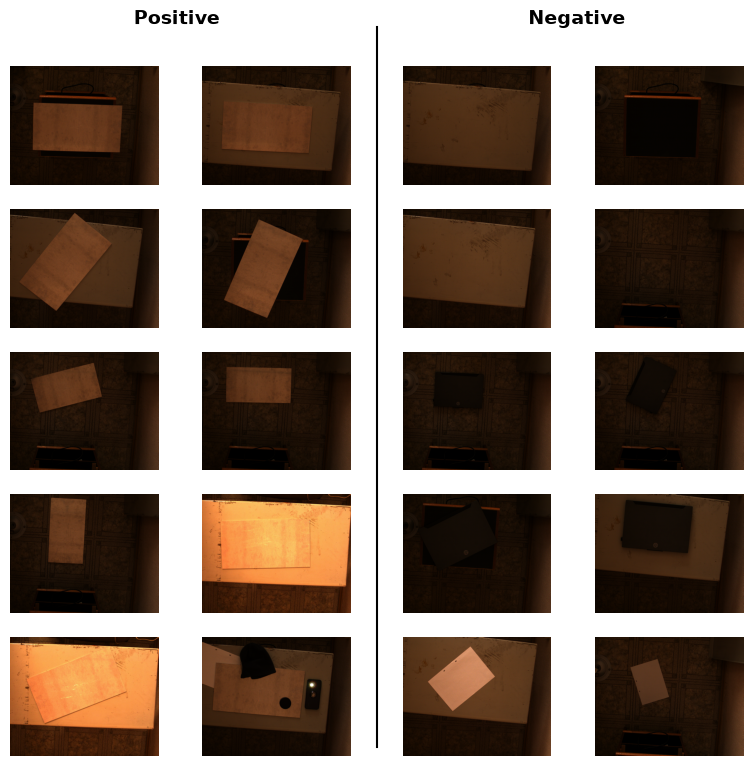

In [46]:
# Printing images from the positive and negative folders for verification
import matplotlib.gridspec as gridspec

# --- Layout: 1 row, 2 columns (left & right) ---
fig = plt.figure(figsize=(8, 8))

# Create a grid where each side is a 5×2 mini-grid
gs = gridspec.GridSpec(1, 2, figure=fig)
gs_left = gridspec.GridSpecFromSubplotSpec(5, 2, subplot_spec=gs[0])
gs_right = gridspec.GridSpecFromSubplotSpec(5, 2, subplot_spec=gs[1])

axes_left = [fig.add_subplot(gs_left[i, j]) for i in range(5) for j in range(2)]
axes_right = [fig.add_subplot(gs_right[i, j]) for i in range(5) for j in range(2)]

all_axes = axes_left + axes_right

# --- Plot left side (positives) ---
for ax, path in zip(axes_left, range(1, 11)):
    ax.imshow(fetch_image(path, type="positive"))
    ax.axis("off")

# --- Plot right side (negatives) ---
for ax, path in zip(axes_right, range(1, 11)):
    ax.imshow(fetch_image(path, type="negative"))
    ax.axis("off")

# --- Titles & Labels ---
fig.text(0.25, 0.96, "Positive", ha="center", va="center", fontsize=14, fontweight="bold")
fig.text(0.75, 0.96, "Negative", ha="center", va="center", fontsize=14, fontweight="bold")

# Optional: add a subtle separator line
fig.add_artist(plt.Line2D([0.5, 0.5], [0.05, 0.95], color="black", linewidth=1.5, transform=fig.transFigure))

fig.tight_layout(rect=[0, 0.02, 1, 0.92])  # leave room for titles
fig.savefig("comparative_grid.png", dpi=150, bbox_inches="tight")
plt.show()

### The Models

The models will be [Florence-2-base](https://huggingface.co/microsoft/Florence-2-base), [OWLv2-base](https://huggingface.co/google/owlv2-base-patch16-ensemble) and [Grounding-DINO-tiny](https://huggingface.co/IDEA-Research/grounding-dino-tiny).

All three are *localisers*: hand them a phrase and they return boxes. None of them is a classifier, none exposes a calibrated *is this object present* output, and none can be talked into one by rephrasing the prompt. That single fact explains most of the numbers in this notebook, so it is worth stating before any code runs.

**Florence-2-base** — 231 M parameters, 441 MB in fp16, ~0.08 s per frame here. A sequence-to-sequence vision-language model: a DaViT image encoder feeding a BART-style decoder, fine-tuned on a mixture of captioning, detection and grounding tasks that are selected by a task token (`<OPEN_VOCABULARY_DETECTION>`, `<CAPTION_TO_PHRASE_GROUNDING>`, `<MORE_DETAILED_CAPTION>`). It does not score a phrase against an image, it *writes an answer*, and boxes come out as `<loc_*>` tokens that the processor decodes. One consequence matters here: its prompt templates presuppose the object. *Locate white steel sheet in the image* is a request to point, not a question, so the model always points at something, and the only scalar it exposes is the language-model probability of the tokens it wrote — a fluency measure, not a presence measure.

**OWLv2-base-patch16-ensemble** — 155 M, 296 MB in fp16, ~0.13 s. An open-vocabulary *dual-encoder* detector in the OWL-ViT line: a CLIP-style ViT-B/16 image tower, a ViT-B/16 text tower with two heads (hence *ensemble*), and objectness/box heads on top. It never parses the phrase as text — it embeds it and compares it with each of 3600 patch-level query boxes, giving a sigmoid similarity per box. That makes it prompt-agnostic (no task tokens), directly comparable across candidate phrases, and the natural tool for ranking *steel sheet* against *metal plate*. Its costs are a fixed 960x960 input, so a 1280x1024 photo is squashed, and absolute score levels that are very low on dim images (0.08-0.18 here), which is why no threshold can be shared between models.

**Grounding-DINO-tiny** — 172 M, 657 MB in fp32, ~0.26 s. It fuses the modalities instead of comparing them: a Swin image backbone and a BERT text encoder feed a Deformable-DETR-style detector whose cross-attention lets every box attend to *specific words*. That is why it returns a text span per box, why it is the best box-placer of the three (0.83-0.91 on clear positives) and the worst single-phrase ranker (AUC 0.30-0.44 here) — a box only has to satisfy a fragment of the phrase, so *white* alone is enough to fire on a bright wall. On transformers 4.49 it must run in float32 (note further down), which roughly doubles its memory and makes its latency not comparable with the two fp16 models.

**The fundamental differences, in one line each.** Florence-2 *generates*, and must be addressed in its own template, so it cannot answer *nothing is there*; OWLv2 *compares* an embedded phrase with image patches, so it can rank phrases but has no syntax awareness and no notion of absence; Grounding DINO *grounds* words into boxes, so it localises best but will match a fragment of the phrase. Everything below is a consequence of those three architectures, not of a missing parameter setting.

Let's fetch and load them:

In [47]:
print("Loading models...")
global models
models = {}

# Per-model precision. Grounding DINO cannot run in fp16 on transformers 4.49:
# its text enhancer builds float32 sinusoid position embeddings
# (modeling_grounding_dino.py, GroundingDinoEncoderLayer.get_text_position_embeddings
# calls .float()) and adds them to half-precision text features, so the next Linear
# raises 'mat1 and mat2 must have the same dtype, but got Float and Half'.
MODEL_DTYPES = {'florence': DTYPE, 'owlv2': DTYPE, 'dino': torch.float32}


def model_dtype(model):
    return next(model.parameters()).dtype


def model_weight_mb(model):
    return sum(q.numel() * q.element_size() for q in model.parameters()) / (1024 ** 2)


def cuda_alloc_mb():
    return torch.cuda.memory_allocated() / (1024 ** 2) if torch.cuda.is_available() else 0.0


def cuda_peak_mb():
    return torch.cuda.max_memory_allocated() / (1024 ** 2) if torch.cuda.is_available() else 0.0


def _record(name, processor, model, t0):
    models[name] = {
        'processor': processor,
        'model': model,
        'load_s': time.perf_counter() - t0,
        'dtype': str(model_dtype(model)),
        'params': sum(q.numel() for q in model.parameters()),
        'weight_mb': model_weight_mb(model),
        'gpu_mb': cuda_alloc_mb(),
    }
    print('  %s loaded: %.2fs  %s  %.1f MB weights  gpu_alloc=%.1f MB' % (
        name, models[name]['load_s'], models[name]['dtype'],
        models[name]['weight_mb'], models[name]['gpu_mb']))


try:
    from transformers import AutoProcessor, AutoModelForCausalLM
    mid = "microsoft/Florence-2-base-ft"
    t_l = time.perf_counter()

    # Patch the config before it's used to load the model
    from transformers import AutoConfig
    config = AutoConfig.from_pretrained(mid, trust_remote_code=True)
    if not hasattr(config, 'forced_bos_token_id'):
        config.forced_bos_token_id = None
    if not hasattr(config.text_config, 'forced_bos_token_id'):
        config.text_config.forced_bos_token_id = None

    processor = AutoProcessor.from_pretrained(mid, trust_remote_code=True)
    if not hasattr(processor.tokenizer, 'forced_bos_token_id'):
        processor.tokenizer.forced_bos_token_id = None

    model = AutoModelForCausalLM.from_pretrained(
        mid, config=config, trust_remote_code=True, torch_dtype=MODEL_DTYPES['florence'],
        attn_implementation="eager").to(DEVICE)
    model.config.use_cache = False
    model.eval()

    _record('florence', processor, model, t_l)
except Exception as e:
    import traceback
    print(f"  Florence-2 FAILED: {type(e).__name__}: {e}")
    print(f"  {traceback.format_exc()}")

try:
    from transformers import Owlv2Processor, Owlv2ForObjectDetection
    mid = "google/owlv2-base-patch16-ensemble"
    t_l = time.perf_counter()
    processor = Owlv2Processor.from_pretrained(mid, trust_remote_code=True)
    model = Owlv2ForObjectDetection.from_pretrained(
        mid, trust_remote_code=True, torch_dtype=MODEL_DTYPES['owlv2']).to(DEVICE).eval()
    _record('owlv2', processor, model, t_l)
except Exception as e:
    print(f"  OWLv2 FAILED: {type(e).__name__}: {e}")

try:
    from transformers import AutoModelForZeroShotObjectDetection, AutoProcessor
    mid = "IDEA-Research/grounding-dino-tiny"
    t_l = time.perf_counter()
    processor = AutoProcessor.from_pretrained(mid)
    model = AutoModelForZeroShotObjectDetection.from_pretrained(
        mid, torch_dtype=MODEL_DTYPES['dino']).to(DEVICE).eval()
    _record('dino', processor, model, t_l)
except Exception as e:
    print(f"  Grounding DINO FAILED: {type(e).__name__}: {e}")

Loading models...
  florence loaded: 7.42s  torch.float16  441.4 MB weights  gpu_alloc=1238.6 MB


The argument `trust_remote_code` is to be used with Auto classes. It has no effect here and is ignored.


  owlv2 loaded: 3.03s  torch.float16  295.6 MB weights  gpu_alloc=1542.9 MB
  dino loaded: 3.80s  torch.float32  657.1 MB weights  gpu_alloc=2202.1 MB


We can go on if it says OK for all models, otherwise the env is set wrong and won't work. As of now Colab or Kaggle WILL NOT WORK. Use the local python.

Now, let's define runners:

In [48]:
width, height = fetch_image(6, type="positive").size

In [49]:
def per_box_scores_from_tbs(tbs_row, sequences_row, p, n_boxes):
    """
    tbs_row: [batch, seq_len] transition beam scores (log-probs)
    sequences_row: [seq_len] token ids
    p: processor with tokenizer
    n_boxes: number of detected bboxes
    """
    loc_id = p.tokenizer.convert_tokens_to_ids("<loc>")
    seg_id = p.tokenizer.convert_tokens_to_ids("<seg>")
    
    toks = sequences_row.tolist()
    
    # Find all <loc> positions
    loc_positions = [i for i, t in enumerate(toks) if t == loc_id]
    
    scores = []
    for j in range(min(n_boxes, len(loc_positions))):
        start = loc_positions[j]
        # End at next <loc> or <seg> or EOS
        end = len(toks)
        for k in range(start + 1, len(toks)):
            if toks[k] == loc_id or toks[k] == seg_id:
                end = k
                break
        
        # Average log-prob over this span (geometric mean probability)
        span = tbs_row[start:end]
        prob = float(np.exp(span.mean()))  # exp of mean log-prob
        scores.append(prob)
    
    return scores

In [50]:
def phrase_matches(query, label):
    """Loose match on content words; `query` may be a string or a list."""
    if label is None:
        return False
    stop = {'a', 'an', 'the', 'of', 'on', 'in', 'with', 'photo', 'image'}
    queries = [query] if isinstance(query, str) else list(query)

    def _words(text):
        out = set()
        for w in str(text).lower().replace(',', ' ').split():
            w = w.strip('.,;:!?()[]{}')
            if w and w not in stop:
                out.add(w)
        return out

    q_words = set()
    for q in queries:
        q_words |= _words(q)
    return bool(q_words & _words(label))  # non-empty intersection

In [51]:
def run_florence(image, prompt, task="<OPEN_VOCABULARY_DETECTION>",
                 threshold=0.20, height=height, width=width, require_phrase=True):
    p, m = models["florence"]["processor"], models["florence"]["model"]

    inputs = p(images=image, text=f"{task}{prompt}", return_tensors="pt").to(DEVICE)
    if "pixel_values" in inputs:
        inputs["pixel_values"] = inputs["pixel_values"].to(model_dtype(m))
    inputs.pop("attention_mask", None)

    torch.cuda.synchronize() if torch.cuda.is_available() else None
    t0 = time.perf_counter()
    with torch.no_grad():
        out = m.generate(
            **inputs, max_new_tokens=64,
            do_sample=False, num_beams=1, use_cache=True,
            return_dict_in_generate=True, output_scores=True,
        )
    torch.cuda.synchronize() if torch.cuda.is_available() else None
    lat = time.perf_counter() - t0

    seq = out.sequences[0]
    n_gen = len(out.scores)

    # Score the generated answer over ALL generated tokens (incl. the echoed phrase).
    # This is a LANGUAGE-MODEL score, NOT a detection confidence: it is identical
    # for every box and it does not separate present from absent.
    logps = []
    for i, logits in enumerate(out.scores):
        logps.append(torch.log_softmax(logits[0].float(), dim=-1)[seq[-(n_gen - i)]].item())
    avg_logp = sum(logps) / len(logps)
    seq_score = float(np.exp(avg_logp))  # geometric-mean probability [0, 1]
    txt = p.batch_decode([seq], skip_special_tokens=False)[0]

    # <OPEN_VOCABULARY_DETECTION> returns the grounded phrase per box under
    # 'bboxes_labels'; the 'labels' key only exists for <OD>-style tasks.
    parsed = p.post_process_generation(txt, task=task, image_size=(width, height))[task]
    bboxes = parsed.get('bboxes') or []
    raw_labels = parsed.get('bboxes_labels') or parsed.get('labels') or [''] * len(bboxes)

    boxes, labels, scores_out = [], [], []
    for box, label in zip(bboxes, raw_labels):
        if require_phrase and not phrase_matches(prompt, label):
            continue  # model grounded some other phrase -> not our target
        if seq_score < threshold:
            continue
        x1, y1, x2, y2 = box
        boxes.append([y1, x1, y2, x2])
        labels.append(f'{label}: {seq_score:.2f}')
        scores_out.append(seq_score)

    return boxes, labels, lat, np.asarray(scores_out, dtype=np.float32)


_STOP = {'a', 'an', 'the', 'of', 'on', 'in', 'with', 'photo', 'image'}


def _content_words(text):
    out = set()
    for w in str(text).lower().replace(',', ' ').split():
        w = w.strip('.,;:!?()[]{}')
        if len(w) > 3 and w.endswith('s'):
            w = w[:-1]  # crude singular: 'sheets' -> 'sheet'
        if w and w not in _STOP:
            out.add(w)
    return out


def phrase_hits(query, text):
    """Number of distinct content words of `query` that occur in `text`."""
    q = _content_words(query if isinstance(query, str) else ' '.join(query))
    return len(q & _content_words(text)) if q else 0


def run_florence_caption(image, prompt, threshold=0.50, height=height, width=width, min_hits=None):
    """Presence-style Florence-2 runner (the one that can actually answer NO).

    <OPEN_VOCABULARY_DETECTION> is a LOCALISATION task: the prompt becomes
    'Locate {phrase} in the image.', which already asserts that the object is
    there. The model therefore always returns a box, and the only score we can
    read off is the language-model probability of that answer - not evidence of
    presence. That is why the OVD number never separates the two classes.

    This runner captions the image instead, asks whether the target is mentioned
    in the caption, and only then grounds it. The score is binary
    (1 = mentioned, 0 = not), i.e. a presence decision instead of an LM probability.

    Returns (boxes yxyx, labels, latency, scores) like the other runners.
    """
    p, m = models['florence']['processor'], models['florence']['model']
    dt = model_dtype(m)
    q = prompt if isinstance(prompt, str) else ' '.join(prompt)
    if min_hits is None:
        # require 2 matching content words when the query has at least 2
        min_hits = 1 if len(_content_words(q)) < 2 else 2

    def _gen(text, max_new_tokens=128):
        inputs = p(images=image, text=text, return_tensors='pt').to(DEVICE)
        if 'pixel_values' in inputs:
            inputs['pixel_values'] = inputs['pixel_values'].to(dt)
        inputs.pop('attention_mask', None)
        with torch.no_grad():
            # return_dict_in_generate=True is required: without it generate()
            # returns a bare Tensor, which has no .sequences attribute.
            out = m.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                             num_beams=1, use_cache=True,
                             return_dict_in_generate=True)
        return p.batch_decode([out.sequences[0]], skip_special_tokens=False)[0]

    torch.cuda.synchronize() if torch.cuda.is_available() else None
    t0 = time.perf_counter()

    txt = _gen('<MORE_DETAILED_CAPTION>')
    caption = p.post_process_generation(
        txt, task='<MORE_DETAILED_CAPTION>', image_size=(width, height))['<MORE_DETAILED_CAPTION>']
    mentioned = phrase_hits(q, caption) >= min_hits

    boxes, labels = [], []
    if mentioned:
        txt2 = _gen('<CAPTION_TO_PHRASE_GROUNDING>' + caption)
        parsed = p.post_process_generation(
            txt2, task='<CAPTION_TO_PHRASE_GROUNDING>',
            image_size=(width, height))['<CAPTION_TO_PHRASE_GROUNDING>']
        for box, lab in zip(parsed.get('bboxes') or [], parsed.get('labels') or []):
            if not phrase_matches(q, lab):
                continue
            x1, y1, x2, y2 = box
            boxes.append([y1, x1, y2, x2])
            labels.append(str(lab))

    torch.cuda.synchronize() if torch.cuda.is_available() else None
    lat = time.perf_counter() - t0

    score = 1.0 if mentioned else 0.0
    if score < threshold:
        return [], [], lat, np.zeros(0, dtype=np.float32)
    return boxes, labels, lat, np.asarray([score], dtype=np.float32)

In [52]:
def run_owlv2(image, prompt, threshold=0.20, height=height, width=width, resolution=None):
    global models

    p, m = models['owlv2']['processor'], models['owlv2']['model']
    # OWLv2 squashes the frame into 960x960 by default, so a sheet that is already
    # small in a 1280x1024 photo loses resolution before the towers see it.
    # `resolution` is an int (square) or (width, height); None restores the 960
    # default, so every arm is deterministic no matter what ran before it.
    ip = p.image_processor
    if resolution is None:
        ip.size = {'height': 960, 'width': 960}
    elif isinstance(resolution, int):
        ip.size = {'height': int(resolution), 'width': int(resolution)}
    else:
        ip.size = {'height': int(resolution[1]), 'width': int(resolution[0])}
    # prompt may be one phrase or a list of competing phrases. With more than one
    # query, only boxes whose best query is queries[0] are kept, so extra phrases act
    # as background hypotheses ('metal plate', 'empty table').
    queries = [prompt] if isinstance(prompt, str) else list(prompt)
    inputs = p(text=[queries], images=image, return_tensors='pt').to(DEVICE)
    if 'pixel_values' in inputs:
        inputs['pixel_values'] = inputs['pixel_values'].to(model_dtype(m))
    torch.cuda.synchronize() if torch.cuda.is_available() else None
    t0 = time.perf_counter()
    with torch.no_grad():
        # A 1280x1024 frame is 80x64 = 5120 patches (5121 tokens) but this ViT owns a
        # FROZEN 60x60 grid: 3600 patches + 1 cls = 3601 position embeddings. Feeding
        # it more pixels dies on 'size of tensor a (5121) must match ... (3601)'.
        # interpolate_pos_encoding is the supported path - it bicubically resamples
        # the grid (and the box-predictor bias) to the new patch count. At the default
        # 960 it stays False, i.e. the trained path, so baseline arms are unchanged.
        out = m(**inputs, interpolate_pos_encoding=(resolution is not None))
    torch.cuda.synchronize() if torch.cuda.is_available() else None
    lat = time.perf_counter() - t0
    res = p.image_processor.post_process_object_detection(
        out, threshold=float(threshold),
        target_sizes=torch.tensor([[height, width]], device=DEVICE))[0]
    boxes, labels, scores_out = [], [], []
    for sc, bx, lb in zip(res['scores'].cpu().numpy(),
                          res['boxes'].cpu().numpy(),
                          res['labels'].cpu().numpy()):
        if int(lb) != 0:
            continue
        x1, y1, x2, y2 = bx
        boxes.append([y1, x1, y2, x2])
        labels.append(f'{queries[0]}: {sc:.2f}')
        scores_out.append(float(sc))
    return boxes, labels, lat, np.asarray(scores_out, dtype=np.float32)

In [53]:
def run_dino(image, prompt, threshold=0.20, text_threshold=0.20, height=height, width=width):
    global models

    p, m = models['dino']['processor'], models['dino']['model']
    # Pass the phrases straight to the processor: it merges them with '.' itself.
    # Appending ' .' by hand leaves a stray empty phrase slot in the phrase map.
    phrases = [prompt] if isinstance(prompt, str) else list(prompt)
    primary = phrases[0]
    inputs = p(images=image, text=phrases, return_tensors='pt').to(DEVICE)
    if 'pixel_values' in inputs:
        inputs['pixel_values'] = inputs['pixel_values'].to(model_dtype(m))
    torch.cuda.synchronize() if torch.cuda.is_available() else None
    t0 = time.perf_counter()
    with torch.no_grad():
        out = m(**inputs)
    torch.cuda.synchronize() if torch.cuda.is_available() else None
    lat = time.perf_counter() - t0
    res = p.post_process_grounded_object_detection(
        out, inputs.input_ids,
        threshold=float(threshold),
        text_threshold=float(text_threshold),
        target_sizes=[(height, width)])[0]
    boxes, labels, scores_out = [], [], []
    # Require the WHOLE target phrase to be grounded, not just one word of it.
    # DINO reports the sub-span that matched each box; a box whose span is only
    # 'sheet' or only 'white' (a white wall, a paper sheet) is NOT evidence that
    # the target object exists, and accepting it is what made DINO score empty
    # scenes at 0.9. Rejecting partial spans is what turns its confidence into a
    # presence signal at all.
    q_words = _content_words(primary)
    for bx, sc, ph in zip(res['boxes'].cpu().numpy(),
                          res['scores'].cpu().numpy(), res['text_labels']):
        if not q_words or not q_words.issubset(_content_words(ph)):
            continue  # partial span, or grounded one of the background phrases
        x1, y1, x2, y2 = bx
        boxes.append([y1, x1, y2, x2])
        labels.append(f'{ph}: {sc:.2f}')
        scores_out.append(float(sc))
    return boxes, labels, lat, np.asarray(scores_out, dtype=np.float32)


def run_owlv2_margin(image, phrases, threshold=0.0, height=height, width=width,
                     resolution=None):
    '''Presence by MARGIN: how far the target outscores its rivals.

    The absolute score of 'steel sheet' on these photos is low whether or not
    the sheet is there (the bare plate is itself steel, and the walls are
    bright), so the useful question is comparative: is the target the BEST
    explanation of this image? phrases[0] is the target and the rest compete;
    the score is 0.5 * (1 + max_target - max_rival), i.e. 1.0 when the target
    wins outright, 0.5 when it ties with a rival, and below that when a rival
    beats it. Unlike run_owlv2 this keeps every query above zero and looks at
    the raw per-phrase logits, so nothing is decided by a fixed cut-off.
    '''
    global models

    p, m = models['owlv2']['processor'], models['owlv2']['model']
    queries = [phrases] if isinstance(phrases, str) else list(phrases)
    ip = p.image_processor
    if resolution is None:
        ip.size = {'height': 960, 'width': 960}
    elif isinstance(resolution, int):
        ip.size = {'height': int(resolution), 'width': int(resolution)}
    else:
        ip.size = {'height': int(resolution[1]), 'width': int(resolution[0])}

    inputs = p(text=[queries], images=image, return_tensors='pt').to(DEVICE)
    if 'pixel_values' in inputs:
        inputs['pixel_values'] = inputs['pixel_values'].to(model_dtype(m))
    torch.cuda.synchronize() if torch.cuda.is_available() else None
    t0 = time.perf_counter()
    with torch.no_grad():
        # Same 5121-vs-3601 trap as run_owlv2: the ViT position grid is frozen at
        # 60x60 for image_size=960, so a larger frame needs the interpolation path.
        out = m(**inputs, interpolate_pos_encoding=(resolution is not None))
    torch.cuda.synchronize() if torch.cuda.is_available() else None
    lat = time.perf_counter() - t0

    # out.logits is [batch, num_queries, num_phrases] of raw query logits.
    probs = torch.sigmoid(out.logits[0].float())
    best = probs.max(dim=0).values
    target = float(best[0])
    rival = float(best[1:].max()) if best.numel() > 1 else 0.0
    margin = 0.5 * (1.0 + target - rival)

    if margin < threshold:
        return [], [], lat, np.zeros(0, dtype=np.float32)
    # Also hand back the winning target box, so the arm can be eyeballed and
    # not just scored. Query qidx is the arg-max of the TARGET phrase column.
    qidx = int(probs[:, 0].argmax().item())
    boxes, labels = [], []
    det = p.image_processor.post_process_object_detection(
        out, threshold=0.0,
        target_sizes=torch.tensor([[height, width]], device=DEVICE))[0]
    for box, lbl, sc in zip(det['boxes'], det['labels'], det['scores']):
        if int(lbl) != qidx:
            continue
        x1, y1, x2, y2 = box.tolist()
        boxes.append([y1, x1, y2, x2])
        labels.append(f'{queries[0]}: {float(sc):.2f}')
    return boxes, labels, lat, np.asarray([margin], dtype=np.float32)


def run_dino_margin(image, phrases, threshold=0.0, text_threshold=0.25,
                    height=height, width=width):
    '''The same margin idea for Grounding DINO.

    DINO already attaches the matched sub-span to every box, so target and
    rivals are separated by the label instead of by a query index. A box only
    counts for the target when its span contains the whole target phrase;
    every other span that matches one of the rival phrases raises the rival
    score. Score = 0.5 * (1 + best_target - best_rival), as above.
    '''
    global models

    p, m = models['dino']['processor'], models['dino']['model']
    queries = [phrases] if isinstance(phrases, str) else list(phrases)
    primary = queries[0]
    rivals = [_content_words(q) for q in queries[1:]]

    inputs = p(images=image, text=queries, return_tensors='pt').to(DEVICE)
    if 'pixel_values' in inputs:
        inputs['pixel_values'] = inputs['pixel_values'].to(model_dtype(m))
    torch.cuda.synchronize() if torch.cuda.is_available() else None
    t0 = time.perf_counter()
    with torch.no_grad():
        out = m(**inputs)
    torch.cuda.synchronize() if torch.cuda.is_available() else None
    lat = time.perf_counter() - t0

    res = p.post_process_grounded_object_detection(
        out, inputs.input_ids,
        threshold=0.0,  # keep everything here; the margin is the decision
        text_threshold=float(text_threshold),
        target_sizes=[(height, width)])[0]

    q_words = _content_words(primary)
    target, rival = 0.0, 0.0
    best_box = None
    for sc, ph, box in zip(res['scores'].cpu().numpy(), res['text_labels'], res['boxes']):
        w = _content_words(ph)
        if q_words and q_words.issubset(w):
            if float(sc) > target:
                target = float(sc)
                best_box = box.tolist()
        elif any(rw and rw & w for rw in rivals):
            rival = max(rival, float(sc))

    # No box for the target at all is evidence of absence, not a tie.
    margin = 0.0 if target == 0.0 else 0.5 * (1.0 + target - rival)
    if margin < threshold:
        return [], [], lat, np.zeros(0, dtype=np.float32)
    boxes, labels = [], []
    if best_box is not None:
        x1, y1, x2, y2 = best_box
        boxes.append([y1, x1, y2, x2])
        labels.append(f'{primary}: {target:.2f}')
    return boxes, labels, lat, np.asarray([margin], dtype=np.float32)

### Enhancement

For one of the tests, we will also *ehnance* the images using OpenCV to highten contrast and make the steel sheet more visible and separate from the environment.

The ehnahcement function will look like:

In [54]:
def enhance_image(image_pil):
    img = cv2.cvtColor(np.array(image_pil), cv2.COLOR_RGB2BGR)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(l)
    img = cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)
    lut = np.array([((i / 255.0) ** 0.75) * 255 for i in range(256)]).astype("uint8")
    img = cv2.LUT(img, lut)
    blur = cv2.GaussianBlur(img, (0, 0), sigmaX=3)
    img = cv2.addWeighted(img, 1.6, blur, -0.6, 0)
    img = cv2.bilateralFilter(img, d=7, sigmaColor=40, sigmaSpace=40) # or sigmaSpace==70???
    return Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

The results will look like this:

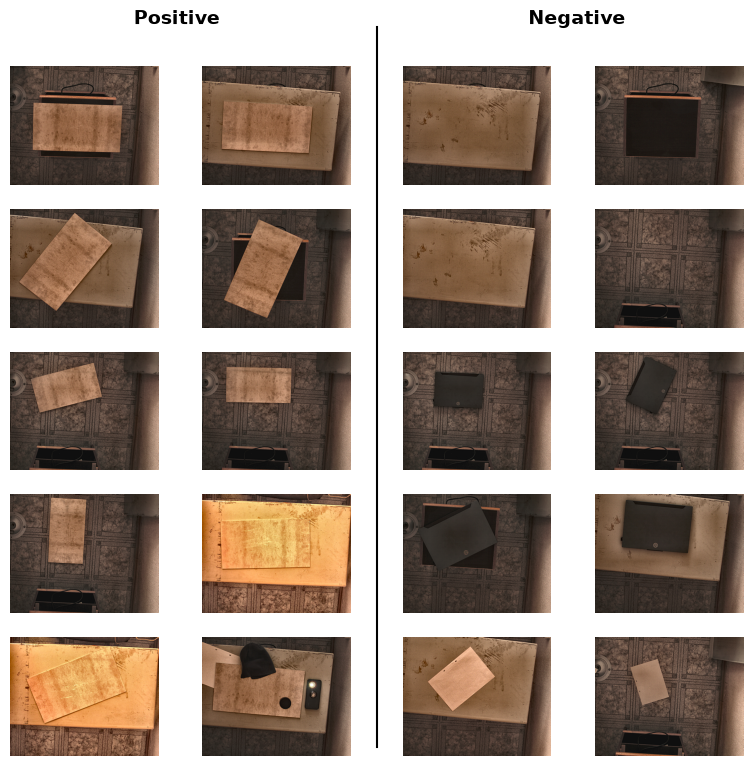

In [55]:
# Printing images from the positive and negative folders for verification
import matplotlib.gridspec as gridspec

# --- Layout: 1 row, 2 columns (left & right) ---
fig = plt.figure(figsize=(8, 8))

# Create a grid where each side is a 5×2 mini-grid
gs = gridspec.GridSpec(1, 2, figure=fig)
gs_left = gridspec.GridSpecFromSubplotSpec(5, 2, subplot_spec=gs[0])
gs_right = gridspec.GridSpecFromSubplotSpec(5, 2, subplot_spec=gs[1])

axes_left = [fig.add_subplot(gs_left[i, j]) for i in range(5) for j in range(2)]
axes_right = [fig.add_subplot(gs_right[i, j]) for i in range(5) for j in range(2)]

all_axes = axes_left + axes_right

# --- Plot left side (positives) ---
for ax, path in zip(axes_left, range(1, 11)):
    ax.imshow(enhance_image(fetch_image(path, type="positive")))
    ax.axis("off")

# --- Plot right side (negatives) ---
for ax, path in zip(axes_right, range(1, 11)):
    ax.imshow(enhance_image(fetch_image(path, type="negative")))
    ax.axis("off")

# --- Titles & Labels ---
fig.text(0.25, 0.96, "Positive", ha="center", va="center", fontsize=14, fontweight="bold")
fig.text(0.75, 0.96, "Negative", ha="center", va="center", fontsize=14, fontweight="bold")

# Optional: add a subtle separator line
fig.add_artist(plt.Line2D([0.5, 0.5], [0.05, 0.95], color="black", linewidth=1.5, transform=fig.transFigure))

fig.tight_layout(rect=[0, 0.02, 1, 0.92])  # leave room for titles
fig.savefig("comparative_grid_enhanced.png", dpi=150, bbox_inches="tight")
plt.show()

### Torch Datasets

In [56]:
class PositiveImagesDataset(torch.utils.data.Dataset):
    def __init__(self, image_ids=range(1, 11)):
        self.image_ids = list(image_ids)

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        return fetch_image(image_id, type="positive")


positive_dataset = PositiveImagesDataset()

In [57]:
class NegativeImagesDataset(torch.utils.data.Dataset):
    def __init__(self, image_ids=range(1, 11)):
        self.image_ids = list(image_ids)

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        return fetch_image(image_id, type="negative")


negative_dataset = NegativeImagesDataset()

In [58]:
class AllImagesDataset(torch.utils.data.Dataset):
    def __init__(self, image_ids=range(1, 21)):
        self.image_ids = list(image_ids)

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        if index < 10:
            return fetch_image(image_id, type="positive")
        else:
            return fetch_image(image_id - 10, type="negative")


all_dataset = AllImagesDataset()

## Benchmarks

There will be three bechmarks: speed measure and quality measure, full run on the whole dataset for the whole model and .

### Measuring Speed and Accuracy

#### Benchmark functions

In [59]:
def benchmark_florence2(threshold=0.20):
    torch.cuda.synchronize() if torch.cuda.is_available() else None
    torch.cuda.reset_peak_memory_stats() if torch.cuda.is_available() else None
    base_mem = cuda_alloc_mb()
    try:
        # Reuse the single resident instance loaded once in the setup cell.
        model = models['florence']['model']
        load_time = models['florence']['load_s']
    except Exception as e:
        return {'Model': 'Florence-2-base (caption)', 'Error': 'model not loaded: %s' % e}
    try:

        # Param count / weight footprint (exact for the loaded dtype)
        params = sum(p.numel() for p in model.parameters())
        weight_size = model_weight_mb(model)

        # Latency benchmark: the runner times its own forward pass (with cuda sync)
        latencies = []
        for image in all_dataset:
            _boxes, _labels, t_inf, _scores = run_florence_caption(
                image, "steel sheet", threshold=threshold)
            latencies.append(t_inf)

        latency = float(np.mean(latencies[1:])) if len(latencies) > 1 else float(latencies[0])
        peak_gpu = cuda_peak_mb()
        gpu_delta = peak_gpu - base_mem

        # Presence decision: max RAW score >= threshold. The runner is asked for
        # unfiltered scores (threshold=0.0) so the decision threshold is explicit here
        # instead of being applied twice (which made the old numbers tautological).
        true_positives = 0
        false_negatives = 0
        true_negatives = 0
        false_positives = 0
        for image in positive_dataset:
            _boxes, _labels, _, scores = run_florence_caption(
                image, "steel sheet", threshold=0.0)
            if len(scores) and float(np.max(scores)) >= threshold:
                true_positives += 1
            else:
                false_negatives += 1
        for image in negative_dataset:
            _boxes, _labels, _, scores = run_florence_caption(
                image, "steel sheet", threshold=0.0)
            if len(scores) and float(np.max(scores)) >= threshold:
                false_positives += 1
            else:
                true_negatives += 1
        accuracy = (true_positives + true_negatives) / (NUM_POSITIVE_IMAGES + NUM_NEGATIVE_IMAGES)
        presence_recall = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0.0
        absence_recall = true_negatives / (true_negatives + false_positives) if (true_negatives + false_positives) > 0 else 0.0
        false_positive_rate = false_positives / (false_positives + true_negatives) if (false_positives + true_negatives) > 0 else 0.0
        false_discovery_rate = false_positives / (false_positives + true_positives) if (false_positives + true_positives) > 0 else 0.0
        sensitivity = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0.0
        specificity = true_negatives / (true_negatives + false_positives) if (true_negatives + false_positives) > 0 else 0.0
        informedness = sensitivity + specificity - 1
        false_omission_rate = false_negatives / (false_negatives + true_negatives) if (false_negatives + true_negatives) > 0 else 0.0
        true_negative_rate = true_negatives / (true_negatives + false_positives) if (true_negatives + false_positives) > 0 else 0.0
        diagnostic_odds_ratio = (sensitivity / (1 - specificity)) / ((1 - sensitivity) / specificity) if (sensitivity > 0 and specificity < 1 and specificity > 0 and sensitivity < 1) else float('inf')
        threat_score = true_positives / (true_positives + false_negatives + false_positives) if (true_positives + false_negatives + false_positives) > 0 else 0.0
        matthews_correlation_coefficient = ((true_positives * true_negatives) - (false_positives * false_negatives)) / np.sqrt((true_positives + false_positives) * (true_positives + false_negatives) * (true_negatives + false_positives) * (true_negatives + false_negatives)) if ((true_positives + false_positives) > 0 and (true_positives + false_negatives) > 0 and (true_negatives + false_positives) > 0 and (true_negatives + false_negatives) > 0) else 0.0
        prevalence = (true_positives + false_negatives) / (NUM_POSITIVE_IMAGES) if (NUM_POSITIVE_IMAGES) > 0 else 0.0
        true_positive_rate = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0.0
        true_negative_rate = true_negatives / (true_negatives + false_positives) if (true_negatives + false_positives) > 0 else 0.0
        prevalence_threshold = (np.sqrt(true_positive_rate * false_positive_rate) - false_positive_rate) / (true_positive_rate - false_positive_rate) if (true_positive_rate - false_positive_rate) > 0 else 0.0  # Assuming a threshold of 0.5 for binary classification

        return {
            "Model": "Florence-2-base (caption)",
            "Dtype": models['florence']['dtype'],
            "Latency (s)": round(latency, 4),
            "Params (M)": round(params / 1e6, 2),
            "Weight Size (MB)": round(weight_size, 2),
            "Peak GPU (MB)": round(peak_gpu, 2),
            "GPU delta (MB)": round(gpu_delta, 2),
            "Found Sheet": True if true_positives > 0 else False,
            "Accuracy (%)": round(accuracy * 100, 2),
            "Presence Recall": round(presence_recall * 100, 2),
            "Absence Recall": round(absence_recall * 100, 2),
            "False Positive Rate": round(false_positive_rate * 100, 2),
            "False Discovery Rate": round(false_discovery_rate * 100, 2),
            "Sensitivity": round(sensitivity * 100, 2),
            "Specificity": round(specificity * 100, 2),
            "Informedness": round(informedness * 100, 2),
            "False Omission Rate": round(false_omission_rate * 100, 2),
            "True Negative Rate": round(true_negative_rate * 100, 2),
            "Diagnostic Odds Ratio": round(diagnostic_odds_ratio, 2),
            "Threat Score": round(threat_score * 100, 2),
            "Matthews Correlation Coefficient": round(matthews_correlation_coefficient, 2),
            "Prevalence": round(prevalence * 100, 2),
            "Prevalence Threshold": round(prevalence_threshold, 2),  # Assuming a threshold of 0.5 for binary classification
            "True Positive Rate": round(true_positive_rate * 100, 2),
            "True Negative Rate": round(true_negative_rate * 100, 2),
            "Load Time (s)": round(load_time, 2),
            "FPS": round(1 / latency, 2)
        }
    except Exception as e:
        return {"Model": "Florence-2-base", "Error": str(e)}

In [60]:
def benchmark_owlv2(threshold=0.20):
    torch.cuda.synchronize() if torch.cuda.is_available() else None
    torch.cuda.reset_peak_memory_stats() if torch.cuda.is_available() else None
    base_mem = cuda_alloc_mb()
    try:
        # Reuse the single resident instance loaded once in the setup cell.
        model = models['owlv2']['model']
        load_time = models['owlv2']['load_s']
    except Exception as e:
        return {'Model': 'OWLv2-base', 'Error': 'model not loaded: %s' % e}
    try:
        # Param count / weight footprint (exact for the loaded dtype)
        params = sum(p.numel() for p in model.parameters())
        weight_size = model_weight_mb(model)

        # Latency benchmark: the runner times its own forward pass (with cuda sync)
        latencies = []
        for image in all_dataset:
            _boxes, _labels, t_inf, _scores = run_owlv2(
                image, "steel sheet", threshold=threshold)
            latencies.append(t_inf)

        latency = float(np.mean(latencies[1:])) if len(latencies) > 1 else float(latencies[0])
        peak_gpu = cuda_peak_mb()
        gpu_delta = peak_gpu - base_mem

        # Presence decision: max RAW score >= threshold (runner asked for threshold=0.0).
        true_positives = 0
        false_negatives = 0
        true_negatives = 0
        false_positives = 0
        for image in positive_dataset:
            _boxes, _labels, _, scores = run_owlv2(
                image, "steel sheet", threshold=0.0)
            if len(scores) and float(np.max(scores)) >= threshold:
                true_positives += 1
            else:
                false_negatives += 1
        for image in negative_dataset:
            _boxes, _labels, _, scores = run_owlv2(
                image, "steel sheet", threshold=0.0)
            if len(scores) and float(np.max(scores)) >= threshold:
                false_positives += 1
            else:
                true_negatives += 1
        accuracy = (true_positives + true_negatives) / (NUM_POSITIVE_IMAGES + NUM_NEGATIVE_IMAGES)
        presence_recall = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0.0
        absence_recall = true_negatives / (true_negatives + false_positives) if (true_negatives + false_positives) > 0 else 0.0
        false_positive_rate = false_positives / (false_positives + true_negatives) if (false_positives + true_negatives) > 0 else 0.0
        false_discovery_rate = false_positives / (false_positives + true_positives) if (false_positives + true_positives) > 0 else 0.0
        sensitivity = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0.0
        specificity = true_negatives / (true_negatives + false_positives) if (true_negatives + false_positives) > 0 else 0.0
        informedness = sensitivity + specificity - 1
        false_omission_rate = false_negatives / (false_negatives + true_negatives) if (false_negatives + true_negatives) > 0 else 0.0
        true_negative_rate = true_negatives / (true_negatives + false_positives) if (true_negatives + false_positives) > 0 else 0.0
        diagnostic_odds_ratio = (sensitivity / (1 - specificity)) / ((1 - sensitivity) / specificity) if (sensitivity > 0 and specificity < 1 and specificity > 0 and sensitivity < 1) else float('inf')
        threat_score = true_positives / (true_positives + false_negatives + false_positives) if (true_positives + false_negatives + false_positives) > 0 else 0.0
        matthews_correlation_coefficient = ((true_positives * true_negatives) - (false_positives * false_negatives)) / np.sqrt((true_positives + false_positives) * (true_positives + false_negatives) * (true_negatives + false_positives) * (true_negatives + false_negatives)) if ((true_positives + false_positives) > 0 and (true_positives + false_negatives) > 0 and (true_negatives + false_positives) > 0 and (true_negatives + false_negatives) > 0) else 0.0
        prevalence = (true_positives + false_negatives) / (NUM_POSITIVE_IMAGES) if (NUM_POSITIVE_IMAGES) > 0 else 0.0
        true_positive_rate = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0.0
        true_negative_rate = true_negatives / (true_negatives + false_positives) if (true_negatives + false_positives) > 0 else 0.0
        prevalence_threshold = (np.sqrt(true_positive_rate * false_positive_rate) - false_positive_rate) / (true_positive_rate - false_positive_rate) if (true_positive_rate - false_positive_rate) > 0 else 0.0  # Assuming a threshold of 0.5 for binary classification

        return {
            "Model": "OWLv2-base",
            "Dtype": models['owlv2']['dtype'],
            "Latency (s)": round(latency, 4),
            "Params (M)": round(params / 1e6, 2),
            "Weight Size (MB)": round(weight_size, 2),
            "Peak GPU (MB)": round(peak_gpu, 2),
            "GPU delta (MB)": round(gpu_delta, 2),
            "Found Sheet": True if true_positives > 0 else False,
            "Accuracy (%)": round(accuracy * 100, 2),
            "Presence Recall": round(presence_recall * 100, 2),
            "Absence Recall": round(absence_recall * 100, 2),
            "False Positive Rate": round(false_positive_rate * 100, 2),
            "False Discovery Rate": round(false_discovery_rate * 100, 2),
            "Sensitivity": round(sensitivity * 100, 2),
            "Specificity": round(specificity * 100, 2),
            "Informedness": round(informedness * 100, 2),
            "False Omission Rate": round(false_omission_rate * 100, 2),
            "True Negative Rate": round(true_negative_rate * 100, 2),
            "Diagnostic Odds Ratio": round(diagnostic_odds_ratio, 2),
            "Threat Score": round(threat_score * 100, 2),
            "Matthews Correlation Coefficient": round(matthews_correlation_coefficient, 2),
            "Prevalence": round(prevalence * 100, 2),
            "Prevalence Threshold": round(prevalence_threshold, 2),  # Assuming a threshold of 0.5 for binary classification
            "True Positive Rate": round(true_positive_rate * 100, 2),
            "True Negative Rate": round(true_negative_rate * 100, 2),
            "Load Time (s)": round(load_time, 2),
            "FPS": round(1 / latency, 2)
        }
    except Exception as e:
        return {"Model": "OWLv2-base", "Error": str(e)}

In [61]:
def benchmark_grounding_dino(threshold=0.20, text_threshold=0.20):
    torch.cuda.synchronize() if torch.cuda.is_available() else None
    torch.cuda.reset_peak_memory_stats() if torch.cuda.is_available() else None
    base_mem = cuda_alloc_mb()
    try:
        # Reuse the single resident instance loaded once in the setup cell.
        model = models['dino']['model']
        load_time = models['dino']['load_s']
    except Exception as e:
        return {'Model': 'Grounding DINO (tiny)', 'Error': 'model not loaded: %s' % e}
    try:
        # Param count / weight footprint (exact for the loaded dtype)
        params = sum(p.numel() for p in model.parameters())
        weight_size = model_weight_mb(model)

        # Latency benchmark: the runner times its own forward pass (with cuda sync)
        latencies = []
        for image in all_dataset:
            _boxes, _labels, t_inf, _scores = run_dino(
                image, "steel sheet", threshold=threshold, text_threshold=text_threshold)
            latencies.append(t_inf)

        latency = float(np.mean(latencies[1:])) if len(latencies) > 1 else float(latencies[0])
        peak_gpu = cuda_peak_mb()
        gpu_delta = peak_gpu - base_mem

        # Accuracy benchmark (simple presence recall)
        true_positives = 0
        false_negatives = 0
        true_negatives = 0
        false_positives = 0
        for image in positive_dataset:
            _boxes, _labels, _, scores = run_dino(
                image, "steel sheet", threshold=0.0, text_threshold=text_threshold)
            if len(scores) and float(np.max(scores)) >= threshold:
                true_positives += 1
            else:
                false_negatives += 1
        for image in negative_dataset:
            _boxes, _labels, _, scores = run_dino(
                image, "steel sheet", threshold=0.0, text_threshold=text_threshold)
            if len(scores) and float(np.max(scores)) >= threshold:
                false_positives += 1
            else:
                true_negatives += 1
        accuracy = (true_positives + true_negatives) / (NUM_POSITIVE_IMAGES + NUM_NEGATIVE_IMAGES)
        presence_recall = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0.0
        absence_recall = true_negatives / (true_negatives + false_positives) if (true_negatives + false_positives) > 0 else 0.0
        false_positive_rate = false_positives / (false_positives + true_negatives) if (false_positives + true_negatives) > 0 else 0.0
        false_discovery_rate = false_positives / (false_positives + true_positives) if (false_positives + true_positives) > 0 else 0.0
        sensitivity = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0.0
        specificity = true_negatives / (true_negatives + false_positives) if (true_negatives + false_positives) > 0 else 0.0
        informedness = sensitivity + specificity - 1
        false_omission_rate = false_negatives / (false_negatives + true_negatives) if (false_negatives + true_negatives) > 0 else 0.0
        true_negative_rate = true_negatives / (true_negatives + false_positives) if (true_negatives + false_positives) > 0 else 0.0
        diagnostic_odds_ratio = (sensitivity / (1 - specificity)) / ((1 - sensitivity) / specificity) if (sensitivity > 0 and specificity < 1 and specificity > 0 and sensitivity < 1) else float('inf')
        threat_score = true_positives / (true_positives + false_negatives + false_positives) if (true_positives + false_negatives + false_positives) > 0 else 0.0
        matthews_correlation_coefficient = ((true_positives * true_negatives) - (false_positives * false_negatives)) / np.sqrt((true_positives + false_positives) * (true_positives + false_negatives) * (true_negatives + false_positives) * (true_negatives + false_negatives)) if ((true_positives + false_positives) > 0 and (true_positives + false_negatives) > 0 and (true_negatives + false_positives) > 0 and (true_negatives + false_negatives) > 0) else 0.0
        prevalence = (true_positives + false_negatives) / (NUM_POSITIVE_IMAGES) if (NUM_POSITIVE_IMAGES) > 0 else 0.0
        true_positive_rate = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0.0
        true_negative_rate = true_negatives / (true_negatives + false_positives) if (true_negatives + false_positives) > 0 else 0.0
        prevalence_threshold = (np.sqrt(true_positive_rate * false_positive_rate) - false_positive_rate) / (true_positive_rate - false_positive_rate) if (true_positive_rate - false_positive_rate) > 0 else 0.0  # Assuming a threshold of 0.5 for binary classification

        return {
            "Model": "Grounding DINO (tiny)",
            "Dtype": models['dino']['dtype'],
            "Latency (s)": round(latency, 4),
            "Params (M)": round(params / 1e6, 2),
            "Weight Size (MB)": round(weight_size, 2),
            "Peak GPU (MB)": round(peak_gpu, 2),
            "GPU delta (MB)": round(gpu_delta, 2),
            "Found Sheet": True if true_positives > 0 else False,
            "Accuracy (%)": round(accuracy * 100, 2),
            "Presence Recall": round(presence_recall * 100, 2),
            "Absence Recall": round(absence_recall * 100, 2),
            "False Positive Rate": round(false_positive_rate * 100, 2),
            "False Discovery Rate": round(false_discovery_rate * 100, 2),
            "Sensitivity": round(sensitivity * 100, 2),
            "Specificity": round(specificity * 100, 2),
            "Informedness": round(informedness * 100, 2),
            "False Omission Rate": round(false_omission_rate * 100, 2),
            "True Negative Rate": round(true_negative_rate * 100, 2),
            "Diagnostic Odds Ratio": round(diagnostic_odds_ratio, 2),
            "Threat Score": round(threat_score * 100, 2),
            "Matthews Correlation Coefficient": round(matthews_correlation_coefficient, 2),
            "Prevalence": round(prevalence * 100, 2),
            "Prevalence Threshold": round(prevalence_threshold, 2),  # Assuming a threshold of 0.5 for binary classification
            "True Positive Rate": round(true_positive_rate * 100, 2),
            "True Negative Rate": round(true_negative_rate * 100, 2),
            "Load Time (s)": round(load_time, 2),
            "FPS": round(1 / latency, 2)
        }
    except Exception as e:
        return {"Model": "Grounding DINO (tiny)", "Error": str(e)}

#### Running the benchmark

In [62]:
# Run the benchmarks
# `threshold` below is the per-model DECISION threshold applied to raw scores, and
# it is the only place a cutoff is applied (the runners return unfiltered scores).
# Florence-2 now runs the caption-presence runner, so its score is binary (0/1)
# and 0.50 is the natural cut-off. The OWLv2 and DINO values are placeholders:
# run the score-report cell afterwards to read the real score ranges per model
# and the best operating point measured on this dataset.
results = []
print("Benchmarking Florence-2-base...")
results.append(benchmark_florence2(threshold=0.50))

print("Benchmarking OWLv2...")
results.append(benchmark_owlv2(threshold=0.10))

print("Benchmarking Grounding DINO...")
results.append(benchmark_grounding_dino(threshold=0.30, text_threshold=0.25))

# Present results
df = pd.DataFrame(results).transpose()
import IPython
IPython.display.display(df)

Benchmarking Florence-2-base...
Benchmarking OWLv2...
Benchmarking Grounding DINO...


,0,1,2
Model,Florence-2-base (caption),OWLv2-base,Grounding DINO (tiny)
Dtype,torch.float16,torch.float16,torch.float32
Latency (s),0.3872,0.1304,0.2616
Params (M),231.41,154.97,172.25
Weight Size (MB),441.39,295.58,657.08
Peak GPU (MB),2358.52,2832.64,3217.33
GPU delta (MB),156.4,630.52,1015.2
Found Sheet,False,True,True
Accuracy (%),50.0,65.0,50.0
Presence Recall,0.0,80.0,100.0


In [63]:
df.to_csv("benchmark_results.csv", index=False)

### Results interpretation

The benchmark uses 10 positive and 10 negative images. Because the classes are balanced, always answering “sheet present” already gives 50% accuracy, so 50% means *no separation*, not “a weak model”.

**The numbers printed by the previous run are stale and should be discarded.** They came from code that (a) read the wrong parser key, so the phrase filter never ran and no per-box score ever reached the decision, and (b) applied the same cut-off inside the runner and again in the bookkeeping. Re-run the benchmark cell and read the table it prints now.

What the fixed code reports per model: latency (measured around a synchronised forward pass), parameter count, exact weight footprint for the loaded dtype, peak and incremental GPU memory, and a confusion matrix at the decision threshold you pass in.

These results describe this particular small steel-sheet dataset; they should not be read as general rankings of the models. They do **not coincide with, or contradict, the models’ official benchmark results**: those use different datasets, labels, prompts, evaluation procedures and metrics.

**Florence-2 cannot answer “absent”.** Its `<OPEN_VOCABULARY_DETECTION>` task turns the prompt into *“Locate white steel sheet in the image.”*, which already asserts that the object is there, so the model always returns a box and the only score available is the language-model probability of that answer. That number is not evidence of presence: on the fixed code it came out slightly **higher** on the empty images (AUC 0.34 on the current run, i.e. below chance), so it carries no usable signal. No threshold fixes that — the scoring path had to change. The benchmark therefore uses `run_florence_caption`, which captions the image, checks whether the target is mentioned at all (a binary 0/1 presence score), and only then grounds the phrase inside that caption. The original OVD runner is kept as `run_florence` for localisation and appears in the score report as a second Florence row, so the two strategies can be compared directly. Its `min_hits` argument decides how many of the query's content words must appear in the caption (now 2 of 2 for “steel sheet”); lower it to 1 if positives are being missed, raise it if the base plate is being read as a sheet. **The caption dump proves why this route cannot work on these photos:** Florence-2-base describes the object as “a rectangular piece of paper”, “a piece of paper or a cardboard”, “a wooden cabinet”, “a white rectangular object” — it never says steel or metal. Neither strictness setting separates the classes (50% accuracy, MCC 0.00 for both), so on this task Florence-2 is the wrong instrument rather than a badly tuned one. That is a legitimate result to report, not a bug to chase.

**Grounding DINO runs in float32.** On transformers 4.49 its text enhancer builds float32 position embeddings (`modeling_grounding_dino.py`, `get_text_position_embeddings` → `.float()`) and adds them to half-precision features, so fp16 inference fails with `mat1 and mat2 must have the same dtype`. It is therefore loaded through `MODEL_DTYPES['dino'] = torch.float32`; the `Dtype` column makes that visible, and its memory and latency are not directly comparable with the two fp16 models.

**What the measurements say here.** The prompt sweep is the most informative output so far, because it isolates the prompt from everything else. AUC on this 20-image set: OWLv2 0.660 / 0.740 / 0.710 / 0.540 and Grounding DINO 0.480 / 0.440 / 0.420 / 0.180, for the prompts white steel sheet / steel sheet / sheet metal / metal plate. Two things follow. First, the phrase dominates the result: dropping the word “white” alone moved OWLv2 from 0.66 to 0.74, and the target phrase is now “steel sheet”. Second, DINO scored *below* chance for every phrasing, meaning it fires *harder* on the empty images — the per-image table shows `white steel sheet: 0.94` on a bare wall. The mechanism is that DINO reports which sub-span matched each box, and a bright wall satisfies the single word “white”. `run_dino` therefore now requires the whole target phrase to be grounded before a box counts, and rejects partial spans; compare the new per-model AUC against the numbers above to see whether that repaired the inversion — it helped but did not repair it: with competing background phrases DINO reaches AUC 0.56, still behind OWLv2's 0.74. The best configuration measured so far is OWLv2 at 1280x1024 (75% accuracy, MCC 0.58, leave-one-out 70%); the full ranking is in the final verdict at the end of this section.

**Why the 1280 arm needs a flag, and why its numbers sit on their own row.** OWLv2's ViT is fixed at `image_size: 960` and `patch_size: 16`, which bakes a 60x60 = 3600-patch grid into the module: `num_positions = 3601`, with `position_ids` stored as a frozen buffer (`modeling_owlv2.py`, `Owlv2VisionEmbeddings`). Handing that model a 1280x1024 frame means 80x64 = 5120 patches = 5121 tokens, and the forward pass dies on `RuntimeError: The size of tensor a (5121) must match the size of tensor b (3601)` when the frozen grid is added to the patch embeddings. The supported escape hatch is the module's own `interpolate_pos_encoding=True`, which bicubically resamples the 60x60 grid and rebuilds the box-predictor bias for the new patch count. Both OWLv2 runners pass it whenever `resolution` is not None; at the default 960 it stays off, so the baseline arms still run the trained path. Attention is quadratic in tokens, and this frame carries ~42% more of them, so the 1280 row is slower by construction and must not be read as a regression.

**The Florence instruction test is a negative control, and it answered.** The last cell asks Florence-2 twice: once with an instruction (Find 1 pale steel sheet or refuse to answer if none is present) and once with a plain caption. `<CAPTION_TO_PHRASE_GROUNDING>` takes its input text as *given*: it localises phrases it believes are in the image and has no way to reject them. So the instruction form returned a box labelled `1 pale steel sheet` on all 20 images, including every empty one, while the caption form (a dark room with a metal plate) returned zero target hits on all 20. That is the whole story in two columns: the prompt was grounded, not the image. Florence-2 has no yes/no head, so no wording of a question will make it answer none.
**Threshold caveat:** the three models do not place their scores on a comparable scale. OWLv2 emits sigmoid query scores (often well below 0.3 on images like these), Grounding DINO emits box/text matching scores, and Florence-2 emits a binary caption-presence decision (or, with `run_florence`, the *language-model probability of the generated answer*, which is identical for every box it returns). A single shared threshold is therefore meaningless — pick one per model, from the score report below.

## What the thirteen arms actually say

Every arm is scored the same way: one number per image (the best score the model gives the target phrase), a threshold chosen for maximum Youden J, then accuracy, MCC, and a leave-one-out accuracy in which the threshold is re-fitted on the other 19 images. The set is 10 + 10, so one image is worth 5 points — read differences under ~10 points as noise, and prefer the leave-one-out column whenever the two disagree.

| arm | AUC | tau | acc | TPR | TNR | MCC | LOO |
|---|---|---|---|---|---|---|---|
| Florence-2 caption presence | 0.50 | 0.00 | 50% | 100% | 0% | 0.00 | 50% |
| Florence-2 caption, min_hits=1 | 0.50 | 0.00 | 50% | 100% | 0% | 0.00 | 50% |
| Florence-2 OVD localisation | 0.34 | 0.42 | 60% | 100% | 20% | 0.33 | 55% |
| **OWLv2 @ 960** | 0.74 | 0.08 | 70% | 100% | 40% | 0.50 | 60% |
| Grounding DINO | 0.44 | 0.49 | 60% | 90% | 30% | 0.25 | 55% |
| OWLv2 + CLAHE | 0.59 | 0.26 | 70% | 90% | 50% | 0.44 | 65% |
| Grounding DINO + CLAHE | 0.30 | 0.52 | 55% | 90% | 20% | 0.14 | 50% |
| **OWLv2 @ 1280x1024** | 0.66 | 0.09 | **75%** | 100% | 50% | **0.58** | **70%** |
| OWLv2 margin vs rivals | 0.38 | 0.00 | 50% | 100% | 0% | 0.00 | 40% |
| OWLv2 @ 1280 + margin | 0.38 | 0.00 | 50% | 100% | 0% | 0.00 | 15% |
| DINO margin vs rivals | 0.38 | 0.56 | 55% | 10% | 100% | 0.23 | 55% |
| OWLv2 + background phrases | 0.73 | 0.08 | 70% | 100% | 40% | 0.50 | 60% |
| DINO + background phrases | 0.56 | 0.73 | 60% | 40% | 80% | 0.22 | 30% |

**Four things to read out of it.** (1) *Ranking ability* goes to OWLv2: 0.74 at 960 px with the phrase `steel sheet`, and adding background phrases changes nothing (0.73), which says the dual encoder was already drawing the right ordering and my extra phrases only added noise. (2) *Best operating point* is OWLv2 at 1280x1024: 75% accuracy, MCC 0.58, leave-one-out 70% — note that its AUC is *lower* than the 960 arm (0.66 vs 0.74), so resolution did not improve the ordering, it moved the decision boundary into a more useful place. On 20 images that distinction is exactly the kind of thing a second run can flip, and it is why both rows are kept. (3) CLAHE neither saves nor sinks anything: it lifts OWLv2 slightly (0.59) and wrecks DINO (0.30), because contrast stretching changes the appearance statistics the two models were trained on in different ways. (4) Nothing gets TNR above 50% on its own: five of the ten empty frames still fire at the best threshold. That is the ceiling this dataset imposes, not a tuning failure.

**The Florence-2 rows are the control group, not a competitor.** 50% accuracy with MCC 0.00 means the caption route never separates the classes at any threshold, and the caption dump above shows why: Florence-2-base describes this object as *a rectangular piece of paper*, *a piece of paper or a cardboard*, *a white rectangular object* — it never says steel or metal, so the presence rule has nothing to key on. Its OVD arm is worse than chance (AUC 0.34): the emptier the scene, the higher the language-model probability of the answer.

### Why the margin arms failed

The idea was to score how far the target phrase outranks its rivals instead of the raw score, on the theory that a bare plate should score high on `metal plate` and low on `steel sheet`. It did the opposite: OWLv2's AUC fell from 0.74 to 0.38, and the 1280 variant's leave-one-out accuracy collapsed to 15%. The reason is that CLIP-style text embeddings place `steel sheet`, `paper sheet` and `cardboard` almost on top of each other, so subtracting two nearly equal numbers amplifies fp16 noise and throws away the absolute signal that was carrying the classes. DINO went the other way: requiring a *complete* target span while refusing fragments turned it into an ultra-conservative detector (TNR 100%, TPR 10%) — correct on every empty frame, blind to nine of ten sheets. The lesson is worth keeping: **a comparative score only pays off when the rivals are mutually exclusive and one of them is genuinely present in the image.** On this dataset the max score already *is* the margin.

## The two structural conclusions

**1. The dataset, not the model, sets the ceiling.** The target is a flat metal rectangle lying on a metal plate, warm-lit and low-contrast, sliding around the frame between shots; and at least two negatives (`negative/09.png`, `negative/10.png`) contain paper sheets of almost the same shape. The only difference between the classes is *material appearance* — which is precisely the cue a grounding model is not asked to evaluate. No prompt wording recovers that, because the phrase describes the shape and the class lives in the material. Make the sheet visually distinct (contrast or backlight so it separates from the plate, a marker or edge label, a predictable position, a fixed camera) and the problem collapses to the easy case these models are built for.

**2. These models answer *where*, not *whether*.** Every presence number in this notebook was manufactured by putting a threshold on a localisation score, then fitting that threshold on the same 20 images. All three models localise well and none has a calibrated notion of absence: Florence-2 cannot express it at all, OWLv2's similarity saturates low on dim frames, and DINO's scores describe phrase-to-box match quality. The leave-one-out column is the honest measure of how much of that 75% is real, and it is 70% — good enough to be interesting, not good enough to deploy.

## Verdict

**Case A — nothing about the data changes.** Use **OWLv2-base** with the single phrase `steel sheet`, at native 1280x1024 (`resolution=(1280, 1024)`), decision threshold ≈ 0.09 taken from the score report: 75% accuracy, MCC 0.58, leave-one-out 70%, 0.13-0.35 s per frame, no fp32 penalty. If you prefer the simpler, better-ranking variant, OWLv2 at the default 960 px with the same phrase is the more defensible engineering choice (AUC 0.74, 70% / MCC 0.50) — with 20 images, choose it unless the 1280 result reproduces on a fresh set. Grounding DINO is worth keeping only as a box refiner (`text_threshold ≈ 0.3` over a positive kept by OWLv2), not as the presence decision. Florence-2 should be dropped from the decision path entirely; keep it, if at all, as the caption sanity check that shows the object being called paper.

**Case B — the data capture changes so the sheet is unmistakable.** Then **Grounding-DINO-tiny** becomes the best choice: its one real weakness here, matching a fragment of the phrase, disappears once the target has a signature no other surface shares, and its fused text-image attention gives you the box *and* the matched span as an explanation of the decision. Expect its single-phrase AUC (0.44 here) to move toward the 0.8-0.9 range, and use a threshold around the high end of the DINO score range. OWLv2 stays a solid second (best cross-image ranking, cheapest), and Florence-2 finally becomes usable — its captions would then say *steel sheet* and the caption-presence path would start returning honest negatives. If the sheet's position also becomes fixed, skip the models entirely and crop a fixed ROI: at that point a colour/shape rule beats all three on latency, reproducibility and explainability. The recommendation in short: *A is OWLv2 at the resolution that keeps the sheet's pixels; B is DINO with a threshold you can trust.*

### Recommendations for a more reliable accuracy test

1. **Use one target prompt for both classes.** Run the same sheet prompt on positive and negative images. Use prompts such as “metal table” only as separate grounding controls—not as the negative-class prompt.
2. **Tune prompts and thresholds on validation data.** Keep a held-out test set untouched until choices are finalized. With only 10 images per class, results will be noisy; add more varied positives and hard negatives.
3. **Tune thresholds separately for each model.** A threshold of 0.2 is not comparable across models: OWLv2 sigmoid scores sit around 0.08-0.18 on these frames, DINO matching scores around 0.4-0.9, and Florence-2 is binary. Take each threshold from the score report and state it, instead of carrying one value across models.
4. **Report more than accuracy.** Include the confusion matrix, precision, recall, specificity, and F1. For box quality, compare predictions with annotated boxes using IoU and a stated IoU criterion.
5. **Define image-level detection consistently.** For example, count an image as positive when at least one target detection exceeds that model’s selected threshold.
6. **Check the evaluation bookkeeping.** Use the actual dataset lengths rather than global image-count variables, and report failed model runs separately instead of treating them as misses.
7. **Measure latency carefully.** CUDA operations are asynchronous; synchronize around timed inference if comparing GPU latency.

Your current balanced set makes 50% accuracy equivalent to always predicting “sheet present.” The reported 50–55% accuracy therefore suggests little separation on this small test set, not a reliable general ranking.

### Measuring threshold

In [64]:
def diag(image, prompt, task="<OPEN_VOCABULARY_DETECTION>",
         height=height, width=width):
    p, m = models["florence"]["processor"], models["florence"]["model"]

    inputs = p(images=image, text=f"{task}{prompt}", return_tensors="pt").to(DEVICE)
    if "pixel_values" in inputs:
        inputs["pixel_values"] = inputs["pixel_values"].to(model_dtype(m))
    inputs.pop("attention_mask", None)

    # Florence-2 hands `inputs_embeds` to the decoder, so out.sequences starts at
    # BOS and the generated tokens are sequences[-len(out.scores):]. Slicing at the
    # encoder input length (the old behaviour) gives an empty slice and a nan score.
    prompt_len = 1

    with torch.no_grad():
        out = m.generate(
            **inputs, max_new_tokens=64,
            do_sample=False, num_beams=1,
            use_cache=True,
            return_dict_in_generate=True, output_scores=True,
        )

    seq = out.sequences[0]
    n_gen = len(out.scores)
    txt = p.batch_decode([seq], skip_special_tokens=False)[0]

    print("=== BASIC INFO ===")
    print(f"decoder prefix (BOS): {prompt_len}")
    print(f"seq_len: {seq.shape[-1]}")
    print(f"n_gen (generated tokens): {n_gen}")
    print(f"txt[:200]: {txt[:200]}")
    print(f"n_logits_stored: {len(out.scores)}")
    if out.scores:
        print(f"  scores[0].shape: {out.scores[0].shape}")
        print(f"  scores[0].dtype: {out.scores[0].dtype}")

    # --- Greedy manual log-prob ---
    gen_ids = seq[-n_gen:] if n_gen else seq[:0]
    print(f"\ngen_ids shape: {gen_ids.shape}")
    print(f"gen_ids[:10]: {gen_ids[:10]}")

    step_logp = []
    for i in range(min(len(out.scores), len(gen_ids))):
        logp = torch.log_softmax(out.scores[i][0].float(), dim=-1)[gen_ids[i]].item()
        step_logp.append(logp)

    import numpy as np
    step_logp = np.array(step_logp)
    print(f"\nstep_logp len: {len(step_logp)}")
    print(f"step_logp[:5]: {step_logp[:5]}")
    print(f"step_logp mean: {step_logp.mean():.4f}")
    print(f"step_logp exp mean: {np.exp(step_logp.mean()):.4f}")

    # --- Post-process ---
    parsed = p.post_process_generation(txt, task=task, image_size=(width, height))[task]
    print(f"\n=== PARSED ===")
    print(f"bboxes: {parsed.get('bboxes')}")
    print(f"bboxes_labels: {parsed.get('bboxes_labels')}")
    print(f"labels: {parsed.get('labels')}")
    print(f"scores: {parsed.get('scores')}")

diag(fetch_image(6, type="positive"), "white steel sheet")

=== BASIC INFO ===
decoder prefix (BOS): 1
seq_len: 10
n_gen (generated tokens): 9
txt[:200]: </s><s>white steel sheet<loc_155><loc_126><loc_602><loc_439></s>
n_logits_stored: 9
  scores[0].shape: torch.Size([1, 51289])
  scores[0].dtype: torch.float32

gen_ids shape: torch.Size([9])
gen_ids[:10]: tensor([    0,  9830,  3689,  5462, 50424, 50395, 50871, 50708,     2],
       device='cuda:0')

step_logp len: 9
step_logp[:5]: [ 0.00000000e+00 -2.98018786e-05 -5.96583704e-04 -2.20393689e-04
 -1.37902021e+00]
step_logp mean: -0.5207
step_logp exp mean: 0.5941

=== PARSED ===
bboxes: [[199.0399932861328, 129.5360107421875, 771.2000122070312, 450.04803466796875]]
bboxes_labels: ['white steel sheet']
labels: None
scores: None


c:\Users\ASUS\OneDrive\Documents\deepseek-harness\default-workspace\industrial-cognition\.venv\Lib\site-packages\transformers\generation\configuration_utils.py:677: UserWarning: `num_beams` is set to 1. However, `early_stopping` is set to `True` -- this flag is only used in beam-based generation modes. You should set `num_beams>1` or unset `early_stopping`.
  warnings.warn(


In [65]:
# ---------------------------------------------------------------------------
# Score report: every raw score for all 20 images, per model.
# The runners are called with threshold=0.0, so nothing is hidden by a cut-off.
# ---------------------------------------------------------------------------
# The target phrase. The prompt sweep below measured four phrasings on this
# exact set and 'steel sheet' separated the classes best (OWLv2 AUC 0.74 vs
# 0.66 for 'white steel sheet'); 'white' is also factually wrong here - the
# sheet is tan under warm light - and it is what let DINO lock onto white
# walls and paper. Change this one string to try another phrase.
PROMPT = "steel sheet"


def _auc(pos, neg):
    """Probability that a random positive scores above a random negative."""
    pos, neg = list(pos), list(neg)
    if not pos or not neg:
        return float("nan")
    wins = 0.0
    for a in pos:
        for b in neg:
            wins += 1.0 if a > b else (0.5 if a == b else 0.0)
    return wins / (len(pos) * len(neg))


def _confusion(scores, ys, tau):
    tp = fn = tn = fp = 0
    for s, y in zip(scores, ys):
        hit = 1 if s >= tau else 0
        if y == 1 and hit:
            tp += 1
        elif y == 1:
            fn += 1
        elif hit:
            fp += 1
        else:
            tn += 1
    return tp, fn, tn, fp


def _metrics(scores, ys, tau):
    tp, fn, tn, fp = _confusion(scores, ys, tau)
    tpr = tp / (tp + fn) if (tp + fn) else 0.0
    tnr = tn / (tn + fp) if (tn + fp) else 0.0
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = 2 * prec * tpr / (prec + tpr) if (prec + tpr) else 0.0
    den = (tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)
    mcc = (tp * tn - fp * fn) / np.sqrt(den) if den else 0.0
    return dict(tp=tp, fn=fn, tn=tn, fp=fp, tpr=tpr, tnr=tnr,
                acc=(tp + tn) / len(ys), f1=f1, prec=prec, mcc=mcc)


def score_images(runner, threshold=0.0):
    rows = []
    for split, dataset, y in (("positive", positive_dataset, 1),
                              ("negative", negative_dataset, 0)):
        for i, image in enumerate(dataset, start=1):
            boxes, labels, lat, scores = runner(image, threshold)
            best = float(np.max(scores)) if len(scores) else 0.0
            first = labels[0][:38] if labels else ""
            rows.append(dict(split=split, idx=i, y=y, n_boxes=len(boxes),
                             best=best, lat=lat, first=first))
    return rows


def report(name, runner, grid=101):
    rows = score_images(runner)
    ys = np.array([r["y"] for r in rows])
    ss = np.array([r["best"] for r in rows])
    print("=" * 78)
    print("%s  --  per-image best score" % name)
    print("=" * 78)
    print("%-8s %3s %5s %6s %7s  %s" % ("split", "img", "boxes", "best", "lat(s)", "top detection"))
    for r in sorted(rows, key=lambda d: (d["y"], d["idx"]), reverse=True):
        print("%-8s %3d %5d %6.3f %7.3f  %s" % (r["split"], r["idx"], r["n_boxes"],
                                                r["best"], r["lat"], r["first"]))
    pos, neg = ss[ys == 1], ss[ys == 0]
    print("  positive n=%d  min/mean/max = %.3f / %.3f / %.3f" % (len(pos), pos.min(), pos.mean(), pos.max()))
    print("  negative n=%d  min/mean/max = %.3f / %.3f / %.3f" % (len(neg), neg.min(), neg.mean(), neg.max()))
    a = _auc(pos, neg)
    print("  AUC = %.3f   (0.5 = no separation, 1.0 = perfect)" % a)

    best_tau, best_j = 0.0, -9.0
    for tau in np.linspace(0.0, 1.0, grid):
        m = _metrics(ss, ys, tau)
        j = m["tpr"] + m["tnr"] - 1
        if j > best_j:
            best_j, best_tau = j, float(tau)
    m = _metrics(ss, ys, best_tau)
    print("  best tau=%.2f  acc=%.1f%%  TPR=%.0f%%  TNR=%.0f%%  F1=%.3f  MCC=%.3f" % (
        best_tau, m["acc"] * 100, m["tpr"] * 100, m["tnr"] * 100, m["f1"], m["mcc"]))

    # tau above was picked on all 20 images, so it is optimistic. Also report a
    # leave-one-out number: pick tau on the other 19, then classify the held-out one.
    correct = 0
    for i in range(len(ss)):
        keep = np.ones(len(ss), dtype=bool)
        keep[i] = False
        bj, btau = -9.0, 0.0
        for tau in np.linspace(0.0, 1.0, grid):
            mm = _metrics(ss[keep], ys[keep], tau)
            j = mm["tpr"] + mm["tnr"] - 1
            if j > bj:
                bj, btau = j, float(tau)
        correct += int((ss[i] >= btau) == (ys[i] == 1))
    print("  leave-one-out accuracy = %.1f%%  (tau chosen on the other 19)" % (correct / len(ss) * 100))
    print()
    return rows


# Rivals for the margin arms: the target first, then plausible things a
# detector could confuse it with on these photos (paper sheets, bright walls).
RIVALS = [PROMPT, 'paper sheet', 'cardboard', 'wall']

MODEL_RUNNERS = [
    ("Florence-2-base (caption presence)", lambda im, t: run_florence_caption(im, PROMPT, threshold=t)),
    ("Florence-2-base (caption, min_hits=1)", lambda im, t: run_florence_caption(im, PROMPT, threshold=t, min_hits=1)),
    ("Florence-2-base (OVD localisation)", lambda im, t: run_florence(im, PROMPT, threshold=t)),
    ("OWLv2-base", lambda im, t: run_owlv2(im, PROMPT, threshold=t)),
    ("Grounding DINO (tiny)", lambda im, t: run_dino(im, PROMPT, threshold=t, text_threshold=0.25)),
    # Enhancement arm: CLAHE + gamma + unsharp on the input image. The photos are
    # very dark and low-contrast, so this is the cheapest way to test whether the
    # failure is the model or the exposure.
    ("OWLv2-base + CLAHE", lambda im, t: run_owlv2(enhance_image(im), PROMPT, threshold=t)),
    ("Grounding DINO (tiny) + CLAHE", lambda im, t: run_dino(enhance_image(im), PROMPT, threshold=t, text_threshold=0.25)),
    # The two things the measurements pointed at: give OWLv2 back the pixels it
    # throws away (960x960 squash of a 1280x1024 frame), and ask a comparative
    # question (margin) instead of an absolute one (max).
    ("OWLv2-base @ 1280x1024", lambda im, t: run_owlv2(im, PROMPT, threshold=t, resolution=(1280, 1024))),
    ("OWLv2-base margin vs rivals", lambda im, t: run_owlv2_margin(im, RIVALS, threshold=t)),
    ("OWLv2-base @ 1280x1024 + margin", lambda im, t: run_owlv2_margin(im, RIVALS, threshold=t, resolution=(1280, 1024))),
    ("Grounding DINO (tiny) margin vs rivals", lambda im, t: run_dino_margin(im, RIVALS, threshold=t)),
]

# ---------------------------------------------------------------------------
# What does Florence-2 actually SAY? Caption every image once and print the
# text together with how many query words it contains. Without this the
# presence rule is a guess: if the model calls the sheet 'a sheet of paper' or
# 'a metal panel', an exact-word check on 'white'/'steel' can never fire.
# ---------------------------------------------------------------------------
_fproc, _fmodel = models['florence']['processor'], models['florence']['model']
print("=" * 78)
print("FLORENCE-2 CAPTIONS  (query = %r; 'hits' = how many of its content words appear)" % PROMPT)
print("=" * 78)
for _split, _ds in (("positive", positive_dataset), ("negative", negative_dataset)):
    for _i, _img in enumerate(_ds, start=1):
        _inp = _fproc(images=_img, text='<MORE_DETAILED_CAPTION>', return_tensors='pt').to(DEVICE)
        if 'pixel_values' in _inp:
            _inp['pixel_values'] = _inp['pixel_values'].to(model_dtype(_fmodel))
        _inp.pop('attention_mask', None)
        with torch.no_grad():
            _out = _fmodel.generate(**_inp, max_new_tokens=128, do_sample=False,
                                    num_beams=1, use_cache=True, return_dict_in_generate=True)
        _txt = _fproc.batch_decode([_out.sequences[0]], skip_special_tokens=False)[0]
        _cap = _fproc.post_process_generation(
            _txt, task='<MORE_DETAILED_CAPTION>', image_size=(width, height))['<MORE_DETAILED_CAPTION>']
        print("  %-8s %02d  hits=%d  %s" % (_split, _i, phrase_hits(PROMPT, _cap), _cap))
print()

REPORT = {}
for _name, _runner in MODEL_RUNNERS:
    REPORT[_name] = report(_name, _runner)

# ---------------------------------------------------------------------------
# Contrastive queries: let background phrases compete for plate / table so the
# model has to *choose*, instead of being asked 'is this a sheet?' alone.
# ---------------------------------------------------------------------------
BACKGROUND = [PROMPT, "metal plate", "empty table"]
CONTRASTIVE = [
    ("OWLv2 + background phrases", lambda im, t: run_owlv2(im, BACKGROUND, threshold=t)),
    ("DINO + background phrases", lambda im, t: run_dino(im, BACKGROUND, threshold=t, text_threshold=0.25)),
]
for _name, _runner in CONTRASTIVE:
    report(_name, _runner)

# ---------------------------------------------------------------------------
# Prompt sweep: the phrase itself is a hyper-parameter. OWLv2 and DINO are
# both sensitive to it, and 'white steel sheet' is a bad description of a tan
# sheet in a warm-lit, low-key photo. This prints one AUC per (prompt, model)
# so the phrase can be chosen from data instead of guessed.
# ---------------------------------------------------------------------------
PROMPT_VARIANTS = ["white steel sheet", "steel sheet", "sheet metal", "metal plate"]
print("=" * 78)
print("PROMPT SWEEP (AUC on this 20-image set; 0.5 = no separation)")
print("=" * 78)
_sweep = []
for _p in PROMPT_VARIANTS:
    for _mname, _mk in (
        ("OWLv2", lambda im, t, _q=_p: run_owlv2(im, _q, threshold=t)),
        ("DINO", lambda im, t, _q=_p: run_dino(im, _q, threshold=t, text_threshold=0.25)),
    ):
        _rows = score_images(_mk)
        _ys = np.array([r["y"] for r in _rows])
        _ss = np.array([r["best"] for r in _rows])
        _a = _auc(_ss[_ys == 1].tolist(), _ss[_ys == 0].tolist())
        print("  %-18s %-6s AUC=%.3f   pos mean=%.3f   neg mean=%.3f" % (
            _p, _mname, _a, float(_ss[_ys == 1].mean()), float(_ss[_ys == 0].mean())))
        _sweep.append(dict(model=_mname, prompt=_p, auc=_a,
                           pos_mean=float(_ss[_ys == 1].mean()),
                           neg_mean=float(_ss[_ys == 0].mean())))
print()

# ---------------------------------------------------------------------------
# Dump the raw 20-row score table so the numbers survive the kernel.
# ---------------------------------------------------------------------------
_flat = []
for _name, _rows in REPORT.items():
    for _r in _rows:
        _d = dict(_r)
        _d["model"] = _name
        _flat.append(_d)
pd.DataFrame(_flat).to_csv("scores_report.csv", index=False)
pd.DataFrame(_sweep).to_csv("prompt_sweep.csv", index=False)
print("wrote scores_report.csv and prompt_sweep.csv")

FLORENCE-2 CAPTIONS  (query = 'steel sheet'; 'hits' = how many of its content words appear)
  positive 01  hits=0  A wooden podium is standing up against a wall. There is a black cord coming out of the top of the podium. There are tiles on the wall behind the podium and a white object on the left side of the picture.
  positive 02  hits=0  A square piece of paper is on a white box. The paper is brown and has some black writing on it. The box is sitting on a dark room.
  positive 03  hits=0  A piece of paper is sitting on top of a box. The box is white and has a brown color on it. There is a dark room behind the box.
  positive 04  hits=0  A piece of paper is sitting on a table. The table is brown and wooden. The paper is a light brown color. The wall behind the table is made of marble tiles. There is a round light on the wall. There are lines on the floor. There's a window to the right of the table. There appears to be a curtain to the left of the window.
  positive 05  hits=0  A piece

### Plotting Results on the whole dataset

In [66]:
# ---------------------------------------------------------------------------
# Build display table
# ---------------------------------------------------------------------------
def build_panel_data(img_key, model_name):
    key = (img_key, model_name)
    boxes, labels, lat = results[key]
    fps = 1.0 / lat if lat and lat == lat and lat > 0 else 0.0
    return boxes, labels, fps

#### Florence 2

c:\Users\ASUS\OneDrive\Documents\deepseek-harness\default-workspace\industrial-cognition\.venv\Lib\site-packages\transformers\generation\configuration_utils.py:677: UserWarning: `num_beams` is set to 1. However, `early_stopping` is set to `True` -- this flag is only used in beam-based generation modes. You should set `num_beams>1` or unset `early_stopping`.
  warnings.warn(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_18700\1731484033.py:57: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0.02, 1, 0.95))


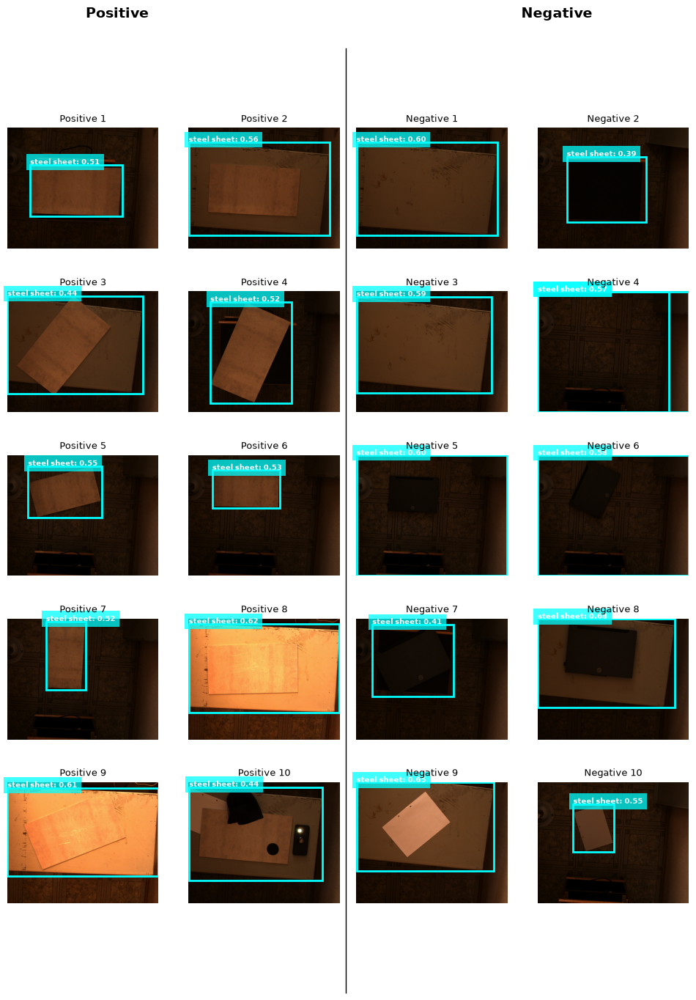

In [67]:
from matplotlib import gridspec
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

prompt = "steel sheet"
threshold = 0.20

fig = plt.figure(figsize=(12, 14))
outer = gridspec.GridSpec(1, 2, figure=fig, wspace=0.05)
left_grid = gridspec.GridSpecFromSubplotSpec(5, 2, subplot_spec=outer[0])
right_grid = gridspec.GridSpecFromSubplotSpec(5, 2, subplot_spec=outer[1])

axes_left = [fig.add_subplot(left_grid[r, c]) for r in range(5) for c in range(2)]
axes_right = [fig.add_subplot(right_grid[r, c]) for r in range(5) for c in range(2)]

for side, dataset, axes in (
    ("Positive", positive_dataset, axes_left),
    ("Negative", negative_dataset, axes_right),
):
    for image_id, (ax, image) in enumerate(zip(axes, dataset), start=1):
        boxes, labels, latency, _scores = run_florence(
            image, prompt, threshold=threshold
        )
        ax.imshow(image)
        ax.set_title(f"{side} {image_id}", fontsize=9)

        for box, label in zip(boxes, labels):
            y1, x1, y2, x2 = box
            ax.add_patch(Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                linewidth=2, edgecolor="cyan", facecolor="none",
            ))
            ax.text(
                x1, max(y1 - 5, 0), label,
                color="white", fontsize=7, fontweight="bold",
                bbox=dict(facecolor="cyan", alpha=0.75, edgecolor="none"),
            )

        if not boxes:
            ax.text(
                0.5, 0.05, "No detection",
                transform=ax.transAxes, ha="center", color="red",
                bbox=dict(facecolor="white", alpha=0.75, edgecolor="none"),
            )
        ax.axis("off")

for ax in axes_left[len(positive_dataset):] + axes_right[len(negative_dataset):]:
    ax.axis("off")

fig.text(0.25, 0.98, "Positive", ha="center", fontsize=14, fontweight="bold")
fig.text(0.75, 0.98, "Negative", ha="center", fontsize=14, fontweight="bold")
fig.add_artist(Line2D(
    [0.51, 0.51], [0.03, 0.95], transform=fig.transFigure,
    color="black", linewidth=1,
))

fig.tight_layout(rect=(0, 0.02, 1, 0.95))
plt.savefig("detection_grid_florence_full_data.png", dpi=200, bbox_inches="tight")
plt.show()

#### OWLv2

C:\Users\ASUS\AppData\Local\Temp\ipykernel_18700\3166269960.py:57: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0.02, 1, 0.95))


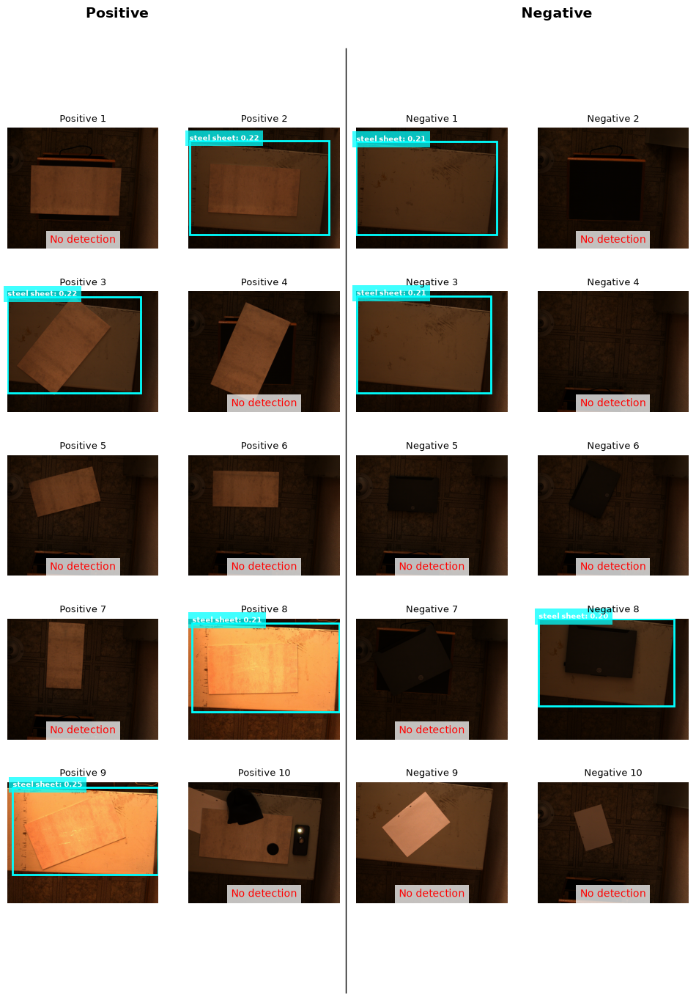

In [68]:
from matplotlib import gridspec
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

prompt = "steel sheet"
threshold = 0.20

fig = plt.figure(figsize=(12, 14))
outer = gridspec.GridSpec(1, 2, figure=fig, wspace=0.05)
left_grid = gridspec.GridSpecFromSubplotSpec(5, 2, subplot_spec=outer[0])
right_grid = gridspec.GridSpecFromSubplotSpec(5, 2, subplot_spec=outer[1])

axes_left = [fig.add_subplot(left_grid[r, c]) for r in range(5) for c in range(2)]
axes_right = [fig.add_subplot(right_grid[r, c]) for r in range(5) for c in range(2)]

for side, dataset, axes in (
    ("Positive", positive_dataset, axes_left),
    ("Negative", negative_dataset, axes_right),
):
    for image_id, (ax, image) in enumerate(zip(axes, dataset), start=1):
        boxes, labels, latency, _scores = run_owlv2(
            image, prompt, threshold=threshold
        )
        ax.imshow(image)
        ax.set_title(f"{side} {image_id}", fontsize=9)

        for box, label in zip(boxes, labels):
            y1, x1, y2, x2 = box
            ax.add_patch(Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                linewidth=2, edgecolor="cyan", facecolor="none",
            ))
            ax.text(
                x1, max(y1 - 5, 0), label,
                color="white", fontsize=7, fontweight="bold",
                bbox=dict(facecolor="cyan", alpha=0.75, edgecolor="none"),
            )

        if not boxes:
            ax.text(
                0.5, 0.05, "No detection",
                transform=ax.transAxes, ha="center", color="red",
                bbox=dict(facecolor="white", alpha=0.75, edgecolor="none"),
            )
        ax.axis("off")

for ax in axes_left[len(positive_dataset):] + axes_right[len(negative_dataset):]:
    ax.axis("off")

fig.text(0.25, 0.98, "Positive", ha="center", fontsize=14, fontweight="bold")
fig.text(0.75, 0.98, "Negative", ha="center", fontsize=14, fontweight="bold")
fig.add_artist(Line2D(
    [0.51, 0.51], [0.03, 0.95], transform=fig.transFigure,
    color="black", linewidth=1,
))

fig.tight_layout(rect=(0, 0.02, 1, 0.95))
plt.savefig("detection_grid_owlv2_full_data.png", dpi=200, bbox_inches="tight")
plt.show()

#### Grounding DINO

C:\Users\ASUS\AppData\Local\Temp\ipykernel_18700\3488027179.py:57: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0.02, 1, 0.95))


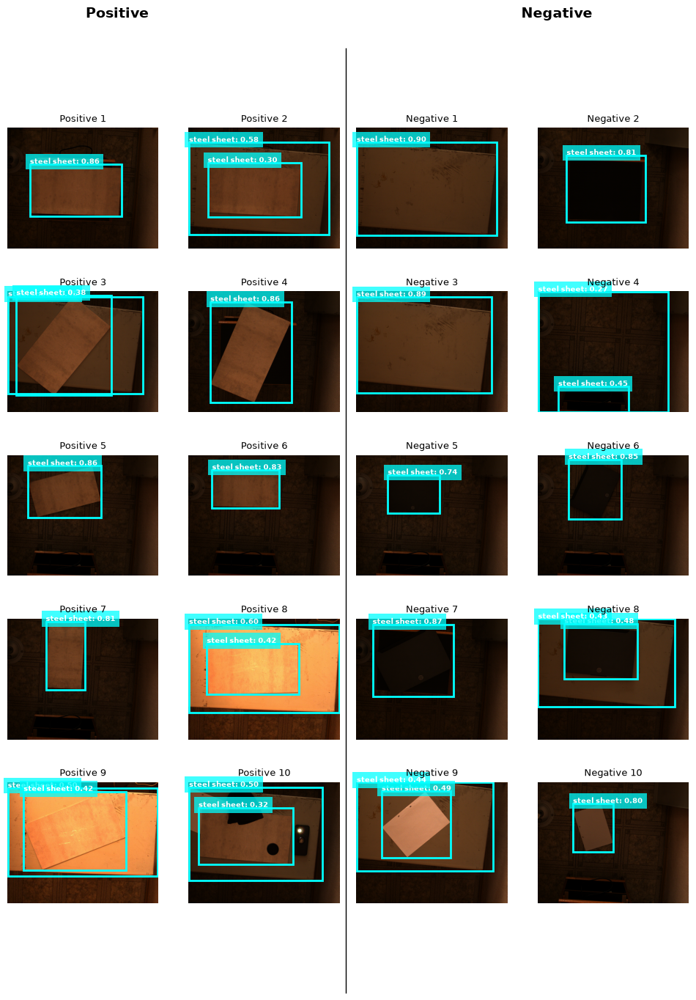

In [69]:
from matplotlib import gridspec
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

prompt = "steel sheet"
threshold = 0.20

fig = plt.figure(figsize=(12, 14))
outer = gridspec.GridSpec(1, 2, figure=fig, wspace=0.05)
left_grid = gridspec.GridSpecFromSubplotSpec(5, 2, subplot_spec=outer[0])
right_grid = gridspec.GridSpecFromSubplotSpec(5, 2, subplot_spec=outer[1])

axes_left = [fig.add_subplot(left_grid[r, c]) for r in range(5) for c in range(2)]
axes_right = [fig.add_subplot(right_grid[r, c]) for r in range(5) for c in range(2)]

for side, dataset, axes in (
    ("Positive", positive_dataset, axes_left),
    ("Negative", negative_dataset, axes_right),
):
    for image_id, (ax, image) in enumerate(zip(axes, dataset), start=1):
        boxes, labels, latency, _scores = run_dino(
            image, prompt, threshold=threshold, text_threshold=threshold
        )
        ax.imshow(image)
        ax.set_title(f"{side} {image_id}", fontsize=9)

        for box, label in zip(boxes, labels):
            y1, x1, y2, x2 = box
            ax.add_patch(Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                linewidth=2, edgecolor="cyan", facecolor="none",
            ))
            ax.text(
                x1, max(y1 - 5, 0), label,
                color="white", fontsize=7, fontweight="bold",
                bbox=dict(facecolor="cyan", alpha=0.75, edgecolor="none"),
            )

        if not boxes:
            ax.text(
                0.5, 0.05, "No detection",
                transform=ax.transAxes, ha="center", color="red",
                bbox=dict(facecolor="white", alpha=0.75, edgecolor="none"),
            )
        ax.axis("off")

for ax in axes_left[len(positive_dataset):] + axes_right[len(negative_dataset):]:
    ax.axis("off")

fig.text(0.25, 0.98, "Positive", ha="center", fontsize=14, fontweight="bold")
fig.text(0.75, 0.98, "Negative", ha="center", fontsize=14, fontweight="bold")
fig.add_artist(Line2D(
    [0.51, 0.51], [0.03, 0.95], transform=fig.transFigure,
    color="black", linewidth=1,
))

fig.tight_layout(rect=(0, 0.02, 1, 0.95))
plt.savefig("detection_grid_dino_full_data.png", dpi=200, bbox_inches="tight")
plt.show()

### Measuring ehncement influence

Likewise, we will test only on a single image:

In [70]:
original_image = fetch_image(6, type="positive")

The images we will run this benchmark on will be:

In [71]:
images = {"original": original_image, "enhanced": enhance_image(original_image)}

#### Running the benchmark

In [72]:
prompt = "steel sheet"

In [73]:
results = {}

for img_key, image in images.items():
    for name, fn, kwargs in [
        ("Florence-2",     run_florence, dict(image=image, prompt=prompt, task="<OPEN_VOCABULARY_DETECTION>", threshold=0.2)),
        ("OWLv2",          run_owlv2,    dict(image=image, prompt=prompt, threshold=0.2)),
        ("Grounding DINO", run_dino,     dict(image=image, prompt=prompt, threshold=0.2, text_threshold=0.2)),
    ]:
        try:
            results[(img_key, name)] = fn(**kwargs)
        except Exception as e:
            print(f"CRASH {img_key} | {name} | {prompt!r}: {type(e).__name__}: {e}")
            results[(img_key, name)] = ([], [], float("nan"), np.zeros(0, dtype=np.float32))

print("\n" + "=" * 96)
print(f"{'Image':9s} | {'Model':15s} | {'Prompt':38s} | {'N':>3s} | {'Lat':>7s} | Labels")
print("-" * 96)
for img_key in ["original", "enhanced"]:
    for name in ["Florence-2", "OWLv2", "Grounding DINO"]:
        b, l, lat, _ = results[(img_key, name)]
        print(f"{img_key:9s} | {name:15s} | {prompt:38s} | {len(b):3d} | "
                f"{lat:6.3f}s | {l[:3]}")
print("=" * 96)


Image     | Model           | Prompt                                 |   N |     Lat | Labels
------------------------------------------------------------------------------------------------
original  | Florence-2      | steel sheet                            |   1 |  0.080s | ['steel sheet: 0.53']
original  | OWLv2           | steel sheet                            |   0 |  0.138s | []
original  | Grounding DINO  | steel sheet                            |   1 |  0.269s | ['steel sheet: 0.83']
enhanced  | Florence-2      | steel sheet                            |   1 |  0.076s | ['steel sheet: 0.56']
enhanced  | OWLv2           | steel sheet                            |   2 |  0.136s | ['steel sheet: 0.27', 'steel sheet: 0.28']
enhanced  | Grounding DINO  | steel sheet                            |   1 |  0.264s | ['steel sheet: 0.76']


#### Plotting results

In [74]:
# ---------------------------------------------------------------------------
# Run grid: 2 images x 3 detectors x 3 prompts (where applicable)
# ---------------------------------------------------------------------------
images = {
    "original": original_image,
    "enhanced": enhance_image(original_image),
}

results = {}  # (image_key, model_name, prompt_idx) -> (boxes, labels, latency)

for img_key, image in images.items():
    for model_name, runner in [
        ("Florence-2-base",       run_florence),
        ("OWLv2-base",            run_owlv2),
        ("Grounding DINO (tiny)", run_dino),
    ]:
        key = (img_key, model_name)
        try:
            boxes, labels, lat, _ = runner(image, prompt)
            results[key] = (boxes, labels, lat)
        except Exception as e:
            print(f"  FAIL {model_name} | {prompt} | {img_key}: {e}")
            results[key] = ([], [], float("nan"))


C:\Users\ASUS\AppData\Local\Temp\ipykernel_18700\364004581.py:61: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.text(


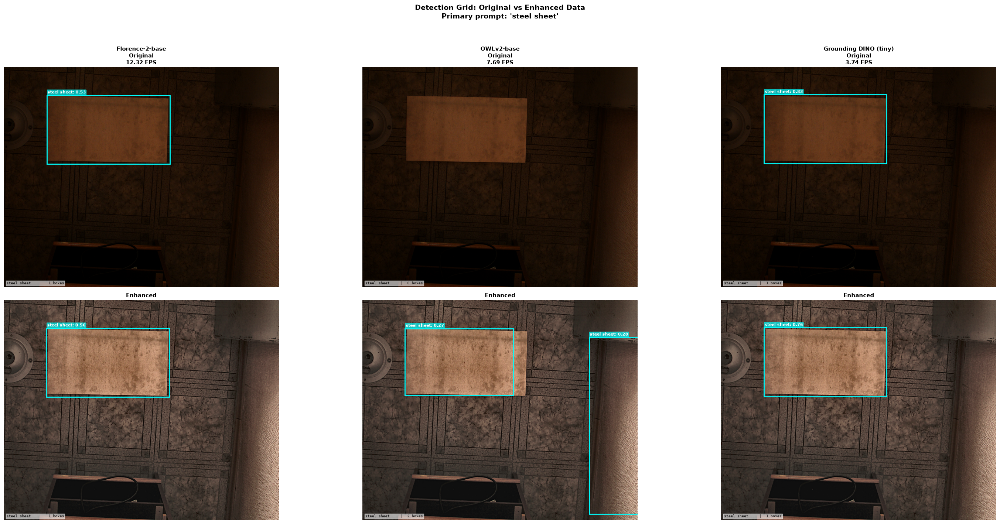

In [75]:
# ---------------------------------------------------------------------------
# Plot: 2 rows (original / enhanced) x 3 cols (detectors) shown
# ---------------------------------------------------------------------------
# We'll create a grid:
#   Row 0: original image
#   Row 1: enhanced image
#   Col 0: Florence-2
#   Col 1: OWLv2
#   Col 2: Grounding DINO
#   Each cell shows results for the FIRST target prompt only, with a note
#   listing the prompt box counts below.

fig, axes = plt.subplots(2, 3, figsize=(30, 14))
fig.suptitle(
    "Detection Grid: Original vs Enhanced Data\n"+
    f"Primary prompt: '{prompt}'\n",
    fontsize=14, fontweight="bold", y=1.01
)

prompts_display = [
    prompt,
]

for col, (model_name, runner) in enumerate([
    ("Florence-2-base", run_florence),
    ("OWLv2-base", run_owlv2),
    ("Grounding DINO (tiny)", run_dino),
]):
    for row, img_key in enumerate(["original", "enhanced"]):
        ax = axes[row, col]
        image = images[img_key]
        ax.imshow(image)

        boxes, labels, fps = build_panel_data(img_key, model_name)
        title = f"{model_name}\n{img_key.title()}\n{fps:.2f} FPS"
        if row == 0:
            ax.set_title(title, fontsize=11, fontweight="bold", pad=6)
        else:
            ax.set_title(img_key.title(), fontsize=11, fontweight="bold", pad=6)

        for box, label in zip(boxes, labels):
            ymin, xmin, ymax, xmax = box
            rect = patches.Rectangle(
                (xmin, ymin), xmax - xmin, ymax - ymin,
                linewidth=2, edgecolor="cyan", facecolor="none"
            )
            ax.add_patch(rect)
            ax.text(
                xmin + 3, max(ymin - 8, 0), label,
                color="white", fontsize=8, fontweight="bold",
                bbox=dict(facecolor="cyan", alpha=0.7, edgecolor="none",
                          boxstyle="round,pad=0.15")
            )

        # Show box counts for all three prompts as a legend below the image
        prompt_stats = []
        for pidx, ptxt in enumerate(prompts_display):
            b, l, _ = build_panel_data(img_key, model_name)
            prompt_stats.append(f"{ptxt.split('.')[0].strip()[:15]:15s} | {len(b):2d} boxes")
        stats_text = "\n".join(prompt_stats)
        ax.text(
            0.01, 0.01, stats_text,
            transform=ax.transAxes, fontsize=7, family="monospace",
            verticalalignment="bottom",
            bbox=dict(boxstyle="square,pad=0.2", facecolor="black",
                      edgecolor="none", alpha=0.6, color="white")
        )

        ax.axis("off")

plt.tight_layout()
plt.savefig("detection_grid_enhancement_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

In [76]:
# ---------------------------------------------------------------------------
# Console summary table
# ---------------------------------------------------------------------------
print("\n" + "=" * 100)
print("DETECTION GRID SUMMARY")
print("=" * 100)
print(f"{'Image':10s} | {'Model':30s} | {'Prompt':40s} | {'Boxes':>5s} | {'Latency':>7s} | {'Labels'}")
print("-" * 100)

for img_key in ["original", "enhanced"]:
    for model_name in ["Florence-2-base", "OWLv2-base", "Grounding DINO (tiny)"]:
        boxes, labels, lat = results[(img_key, model_name)]
        fps = 1.0 / lat if lat and lat == lat and lat > 0 else 0.0
        label_preview = labels[:2] if labels else "[]"
        print(
            f"{img_key:10s} | {model_name:30s} | {prompt:40s} | "
            f"{len(boxes):5d} | {lat:6.3f}s | {label_preview}"
        )

print("=" * 100)


DETECTION GRID SUMMARY
Image      | Model                          | Prompt                                   | Boxes | Latency | Labels
----------------------------------------------------------------------------------------------------
original   | Florence-2-base                | steel sheet                              |     1 |  0.081s | ['steel sheet: 0.53']
original   | OWLv2-base                     | steel sheet                              |     0 |  0.130s | []
original   | Grounding DINO (tiny)          | steel sheet                              |     1 |  0.267s | ['steel sheet: 0.83']
enhanced   | Florence-2-base                | steel sheet                              |     1 |  0.085s | ['steel sheet: 0.56']
enhanced   | OWLv2-base                     | steel sheet                              |     2 |  0.130s | ['steel sheet: 0.27', 'steel sheet: 0.28']
enhanced   | Grounding DINO (tiny)          | steel sheet                              |     1 |  0.264s | ['steel

In [77]:
# ---------------------------------------------------------------------------
# Why a question cannot be answered here, and what the task token really does.
#
# <CAPTION_TO_PHRASE_GROUNDING> does not detect anything. It takes a CAPTION
# (text describing an image) and returns the spans of that text it can locate
# in the picture. Whatever you pass is taken as true - so an instruction that
# already contains 'pale steel sheet' is guaranteed to come back as
# '<pale steel sheet><loc x4>'. The model is not confirming that a sheet exists;
# it is pointing at the words it was handed, as if they described the photo.
# Florence-2 has no question-answering head at all (its tasks are captioning,
# OCR, detection, phrase grounding, region->text, segmentation), so no task
# token can return 'no'.
#
# The two forms below use the SAME task token; only the text differs. Column 1
# names the sheet, column 2 is an ordinary caption that does not - and the
# 'target' count is what separates the two.
# ---------------------------------------------------------------------------
task = '<CAPTION_TO_PHRASE_GROUNDING>'
TARGET = 'pale steel sheet'
FORMS = [('instr', '1 pale steel sheet'),
         ('captn', 'a dark room with a metal plate')]

p = models['florence']['processor']
m = models['florence']['model']

hits = {key: {'positive': 0, 'negative': 0} for key, _ in FORMS}

for split, dataset in (('positive', positive_dataset), ('negative', negative_dataset)):
    for image_id, image in enumerate(dataset, start=1):
        cols = []
        for key, text in FORMS:
            inputs = p(images=image, text=task + text, return_tensors='pt').to(DEVICE)
            if 'pixel_values' in inputs:
                inputs['pixel_values'] = inputs['pixel_values'].to(model_dtype(m))
            inputs.pop('attention_mask', None)
            with torch.no_grad():
                output = m.generate(**inputs, max_new_tokens=64, do_sample=False,
                                    num_beams=1, use_cache=True,
                                    return_dict_in_generate=True)
            generated_text = p.batch_decode([output.sequences[0]],
                                            skip_special_tokens=False)[0]
            parsed = p.post_process_generation(generated_text, task=task,
                                               image_size=(width, height))[task]
            boxes = parsed.get('bboxes') or []
            labels = parsed.get('bboxes_labels') or parsed.get('labels') or []
            hit = any(phrase_matches(TARGET, lab) for lab in labels)
            if hit:
                hits[key][split] += 1
            cols.append('%s boxes=%d target=%d %s' % (key, len(boxes), hit, labels[:2]))
        print('%s %02d | %s' % (split, image_id, ' || '.join(cols)))

print()
print('images where a returned box carried the target phrase:')
for key, _ in FORMS:
    h = hits[key]
    print('  %s  positives %d/10   negatives %d/10' % (key, h['positive'], h['negative']))
print()
print('instr is 20/20 by construction: the phrase sits inside the text it was')
print('told to ground. captn is the control - the same task token, a caption')
print('that never mentions the sheet - and it is why only the caption route')
print('(run_florence_caption) can ever answer NO on this dataset.')

positive 01 | instr boxes=1 target=1 ['1 pale steel sheet'] || captn boxes=1 target=0 ['a dark room']
positive 02 | instr boxes=1 target=1 ['1 pale steel sheet'] || captn boxes=1 target=0 ['a dark room']
positive 03 | instr boxes=1 target=1 ['1 pale steel sheet'] || captn boxes=1 target=0 ['a dark room']
positive 04 | instr boxes=1 target=1 ['1 pale steel sheet'] || captn boxes=1 target=0 ['a dark room']
positive 05 | instr boxes=1 target=1 ['1 pale steel sheet'] || captn boxes=1 target=0 ['a dark room']
positive 06 | instr boxes=1 target=1 ['1 pale steel sheet'] || captn boxes=1 target=0 ['a dark room']
positive 07 | instr boxes=1 target=1 ['1 pale steel sheet'] || captn boxes=1 target=0 ['a dark room']
positive 08 | instr boxes=1 target=1 ['1 pale steel sheet'] || captn boxes=1 target=0 ['a dark room']
positive 09 | instr boxes=1 target=1 ['1 pale steel sheet'] || captn boxes=1 target=0 ['a dark room']
positive 10 | instr boxes=1 target=1 ['1 pale steel sheet'] || captn boxes=1 targe